In [55]:
import pandas as pd

df = pd.read_csv('./track_2024/track_202405_59km.csv', usecols=[10])

print(len(df))

print(df.head())

137661492
   SOG:Float
0       43.8
1        0.0
2        0.0
3        0.0
4        0.0


In [58]:
print(type(df.iloc[0][0]))
print(df.iloc[0][0])


<class 'numpy.float64'>
43.8


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11296\2535169931.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(type(df.iloc[0][0]))
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11296\2535169931.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(df.iloc[0][0])


In [ ]:
import json
import numpy as np

seri = df.squeeze()

all_cordi = []
for i in range(len(seri)):
    a = seri.iloc[i]
    b=a.split('(')[1].split(')')[0]
    c = b.split(' ')
    d = [np.float32(item) for item in c]
    
    all_cordi.append(d)
    
# f = open('all_cordi_1.json', 'w')
# json.dump(all_cordi, f, ensure_ascii=False)
# f.close()

np.save('cordi_5.npy', all_cordi)

In [ ]:
import numpy as np
import os
import pandas as pd

dir_path = './track_2024/'
file_list = os.listdir(dir_path)
print(file_list)

total_count = 0
all_cordi = []

for file in file_list:
    if file.endswith('.csv'):
        file_path = os.path.join(dir_path, file)
        df = pd.read_csv(file_path, usecols=[8])
        seri = df.squeeze()

        for i in range(len(seri)):
            
            a = seri.iloc[i]
            b=a.split('(')[1].split(')')[0]
            c = b.split(' ')
            d = [np.float32(item) for item in c]
            if i<3:
                print(d)
                
            all_cordi.append(d)
            total_count += 1
            
            if total_count % 100000000 == 0:
                num_saved = total_count // 100000000
                np.save('./track_2024/'+str(num_saved)+'.npy', all_cordi)
                all_cordi = []  # Clear the list after saving
            
# Save any remaining coordinates after processing all files
if all_cordi:
    num_saved = total_count//100000000+1
    np.save('./track_2024/'+str(num_saved)+'.npy', all_cordi)


In [ ]:
# 运行到track_202501_59km.csv时发生了问题，即读取这个文件时发生了错误，前面到track_202412_59km.csv的都正常，累计了892560445个点，保存了前面8亿，
# 剩下92560445个点没有保存，['track_202405_59km.csv', 'track_202406_59km.csv', 'track_202407_59km.csv', 'track_202408_59km.csv', 'track_202409_59km.csv', 'track_202410_59km.csv', 'track_202411_59km.csv', 'track_202412_59km.csv', 'track_202501_59km.csv', 'track_202502_59km.csv', 'track_202504_59km.csv', 'track_202505_59km.csv']

import numpy as np
np.save('./track_2024/9.npy', all_cordi)

In [1]:

chunk_size = 10000000


import numpy as np
import os
import pandas as pd

dir_path = './track_2024/'
# file_list = os.listdir(dir_path)
# print(file_list)

total_count = 0
all_cordi = []

file_list = ['track_202405_59km.csv', 'track_202406_59km.csv', 'track_202407_59km.csv', 'track_202408_59km.csv', 'track_202409_59km.csv', 'track_202410_59km.csv', 'track_202411_59km.csv', 
 'track_202412_59km.csv', 'track_202501_59km.csv', 'track_202502_59km.csv', 'track_202504_59km.csv', 'track_202505_59km.csv']
print(len(file_list))

for file in file_list:
    if file.endswith('.csv'):
        file_path = os.path.join(dir_path, file)
        # df = pd.read_csv(file_path, usecols=[8])
        for chunk in pd.read_csv(file_path, chunksize=chunk_size, usecols=[8, 10]):   
        
            seri = chunk.iloc[:, 0]
            speed = chunk.iloc[:, 1]

            for i in range(len(seri)):
                
                a = seri.iloc[i]
                b=a.split('(')[1].split(')')[0]
                c = b.split(' ')
                d = [np.float32(item) for item in c]
                if i<1:
                    print(d)
                    print(speed.iloc[i])
                
                if speed.iloc[i] > 1.0:
                    all_cordi.append(d)
                    total_count += 1
                
                if total_count % 100000000 == 0:
                    num_saved = total_count // 100000000
                    np.save('./track_2024/'+str(num_saved)+'_filter_.npy', all_cordi)
                    all_cordi = []  # Clear the list after saving
            del chunk
            
# Save any remaining coordinates after processing all files
if all_cordi:
    num_saved = total_count//100000000+1
    np.save('./track_2024/'+str(num_saved)+'_filter_.npy', all_cordi)

12
[110.95983, 30.570362]
43.8
[111.02983, 30.833868]
0.07
[110.8858, 30.894886]
0.14
[110.946915, 30.869867]
0.06
[110.925415, 30.875242]
0.07
[110.923225, 30.877943]
0.12
[111.09294, 30.85791]
0.12
[111.38988, 30.588818]
0.09
[111.377525, 30.60484]
0.18
[111.38371, 30.598373]
0.06
[111.369576, 30.612906]
0.16
[111.35805, 30.619709]
5.16
[111.29983, 30.681973]
0.1
[111.22607, 30.770002]
0.0
[111.0, 30.603212]
0.0
[111.05715, 30.837082]
4.4
[110.94079, 30.866217]
0.0
[110.951775, 30.871218]
0.12
[110.93155, 30.872921]
0.0
[111.07662, 30.85077]
0.02
[111.38938, 30.591341]
0.04
[111.38053, 30.598839]
0.04
[111.36372, 30.61624]
0.14
[111.26809, 30.74662]
4.79
[111.1907, 30.772274]
0.09
[111.0, 30.577034]
0.1
[110.90993, 30.889206]
4.7
[110.947716, 30.86947]
0.25
[110.92635, 30.874664]
0.14
[110.931725, 30.879536]
7.4
[111.3878, 30.59126]
0.2
[111.37535, 30.60607]
0.12
[111.366035, 30.613958]
0.09
[111.35853, 30.625195]
0.0
[111.14767, 30.788187]
0.0
[111.0, 30.57809]
0.0
[111.07189, 30.84

In [ ]:
points = [[110.95983, 30.570362],
[111.02983, 30.833868],
[110.8858, 30.894886],
[110.946915, 30.869867],
[110.925415, 30.875242],
[110.923225, 30.877943],
[111.09294, 30.85791],
[111.38988, 30.588818],
[111.377525, 30.60484],
[111.38371, 30.598373],
[111.369576, 30.612906],
[111.35805, 30.619709],
[111.29983, 30.681973],
[111.22607, 30.770002],
[111.0, 30.603212],
[111.05715, 30.837082],
[110.94079, 30.866217],
[110.951775, 30.871218],
[110.93155, 30.872921],
[111.07662, 30.85077],
[111.38938, 30.591341],
[111.38053, 30.598839],
[111.36372, 30.61624],
[111.26809, 30.74662],
[111.1907, 30.772274],
[111.0, 30.577034],
[110.90993, 30.889206],
[110.947716, 30.86947],
[110.92635, 30.874664],
[110.931725, 30.879536],
[111.3878, 30.59126],
[111.37535, 30.60607],
[111.366035, 30.613958],
[111.35853, 30.625195],
[111.14767, 30.788187],
[111.0, 30.57809],
[111.07189, 30.846682],
[110.94726, 30.868582],
[110.92651, 30.873716],
[110.92261, 30.88103],
[111.35141, 30.624186],
[111.37619, 30.603685],
[111.37987, 30.59973],
[111.363014, 30.616436],
[111.26874, 30.748486],
[111.18605, 30.77523],
[111.0, 30.581963],
[111.06677, 30.842089],
[110.9472, 30.869074],
[110.91819, 30.878191],
[111.39485, 30.580341],
[111.376434, 30.603895],
[111.372246, 30.610123],
[111.26912, 30.7011],
[111.212, 30.772799],
[111.0, 30.580112],
[111.006355, 30.84064],
[110.934944, 30.869125],
[110.97614, 30.850954],
[110.918106, 30.878216],
[111.080475, 30.853325],
[111.386665, 30.590233],
[111.369354, 30.60637],
[111.36659, 30.613344],
[111.36205, 30.616688],
[111.29977, 30.681915],
[111.16086, 30.800968],
[110.989265, 30.58439],
[111.00905, 30.83965],
[110.93124, 30.866648],
[110.95028, 30.870018],
[110.92663, 30.874575],
[110.9515, 30.879751],
[111.39375, 30.58006],
[111.37893, 30.601912],
[111.38271, 30.597754],
[111.36887, 30.611275],
[111.3602, 30.620102],
[111.28163, 30.729273],
[111.25436, 30.766098],
[111.0, 30.57108],
[111.009575, 30.839554],
[110.9311, 30.865168],
[110.94588, 30.869501],
[110.92611, 30.874844],
[110.95222, 30.875875],
[111.091034, 30.856892],
[111.37743, 30.60091],
[111.37562, 30.607204],
[111.37182, 30.609371],
[111.359924, 30.619726],
[111.2837, 30.731485],
[111.2257, 30.769741],
[111.0, 30.583494],
[111.0547, 30.836521],
[110.94209, 30.865004],
[110.92698, 30.873968],
[110.953415, 30.879793],
[111.38991, 30.584747],
[111.37913, 30.602411],
[111.379776, 30.601223],
[111.36949, 30.61148],
[111.317924, 30.662107],
[111.290016, 30.741463],
[111.10228, 30.856438],
[111.0, 30.589296],
[110.89225, 30.887852],
[110.94907, 30.870531],
[110.9223, 30.877645],
[111.391785, 30.585884],
[111.37424, 30.605173],
[111.37163, 30.609324],
[111.26253, 30.70811],
[111.18483, 30.775387],
[108.47313, 30.834982],
[111.60513, 30.290558],
[111.599976, 30.280514],
[108.82052, 30.955467],
[110.81887, 30.938738],
[110.39868, 31.037745],
[111.50325, 30.322382],
[109.52303, 31.041348],
[111.417816, 30.510014],
[110.951256, 30.87206],
[108.50187, 30.876993],
[111.0, 30.58037],
[111.010735, 30.839415],
[110.9294, 30.866014],
[110.952194, 30.87052],
[110.9244, 30.876818],
[111.07675, 30.850374],
[111.356514, 30.622252],
[111.37894, 30.603176],
[111.381065, 30.601192],
[111.36347, 30.616373],
[111.26556, 30.740353],
[111.17534, 30.776981]]
print(len(points))

import pandas as pd

track_id = []
point_order = []
longitude = []
latitude = []

for i in range(len(points)):
    track_id.append(i)
    point_order.append(i)
    longitude.append(points[i][0])
    latitude.append(points[i][1])
    
df = pd.DataFrame({'track_id': track_id, 'point_order': point_order, 'longitude': longitude, 'latitude': latitude})
df.to_csv(f'ais.csv', index=False, encoding='utf-8')


In [2]:
import numpy as np
import os
import pandas as pd
from pyproj import Transformer

transformer = Transformer.from_crs("epsg:4326", "epsg:32649", always_xy=True)


dir_path = './track_2024/'
# file_list = os.listdir(dir_path)
# print(file_list)
file_list = ['1_filter_.npy', '2_filter_.npy', '3_filter_.npy']

max_x = -100000.0
min_y = 1000000.0

file_cout = 0
for file in file_list:
    
    
    if file.endswith('.npy'):
        
        file_cout += 1
        
        file_write = os.path.join(dir_path, f'utm_{file_cout}_filter.npy')
        
        file_read = os.path.join(dir_path, file)
        cordi = np.load(file_read)
        
        utm_cordi = np.zeros_like(cordi)
        
        for i in range(len(cordi)):
            x, y = transformer.transform(cordi[i, 0], cordi[i, 1])
            utm_cordi[i, 0] = x
            utm_cordi[i, 1] = y
            if i<5:
                print(x, y)
            
            if x > max_x:
                max_x = x
            if y < min_y:
                min_y = y
        np.save(file_write, utm_cordi)

print(max_x, min_y)

496148.161590877 3381989.5305125285
490901.2919944166 3387338.8364614914
500000.00000000367 3389968.245633863
500000.00000000367 3395089.3472435963
508689.58507226425 3402257.355944272
529358.2405366086 3393548.979618717
529035.2337438153 3393813.5893669524
529035.9634014458 3393814.0140855582
525426.6435178575 3400865.643889859
525427.3783434972 3400863.7432478527
514893.92020190944 3405126.410312989
514895.38142428786 3405125.5668417267
514903.4172693647 3405121.561879208
521379.4388404012 3404413.2140221237
521378.7062361113 3404414.4808184113
646772.1075347738 1000000.0


In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


x_min = 495000.0
x_max = 535000.0

y_min = 3385000.0
y_max = 3420000.0

row_num = (int(y_max) - int(y_min)) // 10
col_num = (int(x_max) - int(x_min)) // 10
print(row_num, col_num)

heatmap = np.zeros((row_num, col_num))

for i in range(1, 15):
    file_path = f'./track_2024/utm_{i}.npy'
    cordi = np.load(file_path)
    
    for j in range(len(cordi)):
        x = cordi[j, 0]
        y = cordi[j, 1]
        
        
        if x < x_min or x >= x_max or y < y_min or y >= y_max:
            continue
        
        I = int((x - x_min)/10)
        J = int((y - y_min)/10)
        if j < 1:
            print(x, y, I, J)
        
        heatmap[J, I] += 1
    print('finished file', i)

np.save('./heatmap.npy', heatmap)

plt.figure()
sns.heatmap(heatmap, annot=True, fmt='.2f',cmap='coolwarm',cbar=True)# 显示颜色条
plt.title('Seaborn Heatmap')
plt.show()





In [12]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


x_min = 501975.0
x_max = 516975.0

y_min = 3403000.0
y_max = 3415000.0

row_num = (int(y_max) - int(y_min)) // 10
col_num = (int(x_max) - int(x_min)) // 10
print(row_num, col_num)

heatmap = np.zeros((row_num, col_num))

train_pts = []
test_pts = []

for i in range(1, 4):
    file_path = f'./track_2024/utm_{i}_filter.npy'
    cordi = np.load(file_path)
    
    for j in range(len(cordi)):
        x = cordi[j, 0]
        y = cordi[j, 1]
        
        
        if x < x_min or x >= x_max or y < y_min or y >= y_max:
            continue
        
        I = int((x - x_min)/10)
        J = int((y - y_min)/10)
        if j < 1:
            print(x, y, I, J)
        
        heatmap[J, I] += 1
        
        if np.random.rand() < 0.7:
            train_pts.append([x-x_min, y-y_min])
        else:
            test_pts.append([x-x_min, y-y_min])
            
    print('finished file', i)

np.save('./train_pts_filter.npy', np.array(train_pts))
np.save('./test_pts_filter.npy', np.array(test_pts))

np.save('./heatmap_small_filter.npy', heatmap)






1200 1500
finished file 1
finished file 2
514893.9 3405126.5 1291 212
finished file 3


17288.0
(1200, 1500)


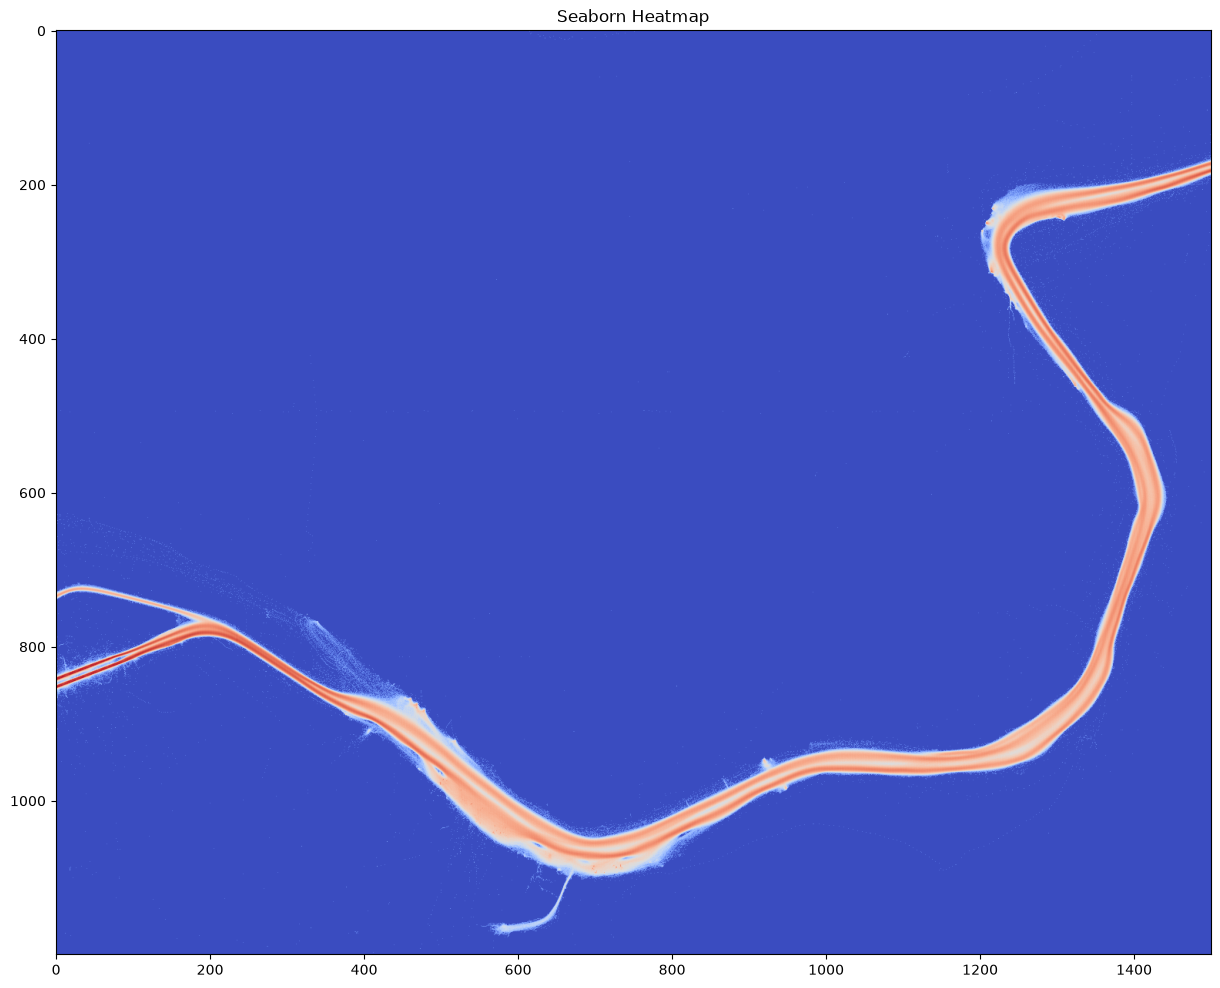

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

heatmap = np.load('heatmap_small_filter.npy')
# heatmap = np.flip(heatmap, axis=0)
print(np.max(heatmap))
print(heatmap.shape)

plt.figure(figsize=(15,12))
# sns.heatmap(heatmap, annot=True, fmt='.2f',cmap='coolwarm',cbar=True)# 显示颜色条
plt.imshow(np.log1p(heatmap), cmap='coolwarm')
plt.title('Seaborn Heatmap')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

heatmap = np.load('heatmap_small.npy')

max_value = np.max(heatmap)
mean_value = np.mean(heatmap)
std_value = np.std(heatmap)

print(max_value)
print(mean_value)
print(std_value)

res = np.clip(heatmap, None, 8000)
res = res / 2000

res = np.flip(res, axis=0)

plt.figure()
# sns.heatmap(res, annot=True, fmt='.2f',cmap='coolwarm',cbar=True)# 显示颜色条
plt.imshow(res, cmap='viridis', aspect='auto', interpolation='nearest')

plt.colorbar(label='值')
# plt.title('Seaborn Heatmap')
plt.show()

result_vertical = gaussian_filter1d(res, sigma=1.5, axis=0)
final_result = gaussian_filter1d(result_vertical, sigma=1.5, axis=1)

print(final_result.shape)

plt.figure(1)
# sns.heatmap(res, annot=True, fmt='.2f',cmap='coolwarm',cbar=True)# 显示颜色条
plt.imshow(final_result, cmap='viridis', aspect='auto', interpolation='nearest')

plt.colorbar(label='值')
# plt.title('Seaborn Heatmap')
plt.show()

(1200, 1500)
1. 正在进行对数压缩与高斯平滑...
2. 正在进行百分位阈值分割...
3. 正在进行形态学清理...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_47056\2119790477.py:119: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  cleaned_mask = remove_small_objects(cleaned_mask, min_size=5000)


4. 正在提取拓扑骨架...
提取完成！共提取出 2428 个脊线像素点。


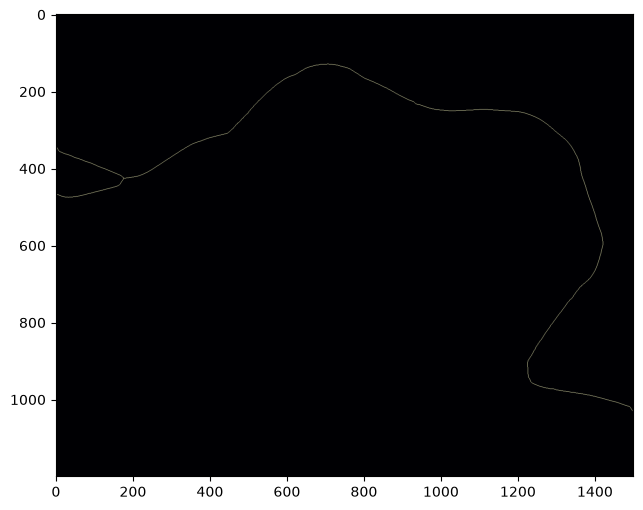

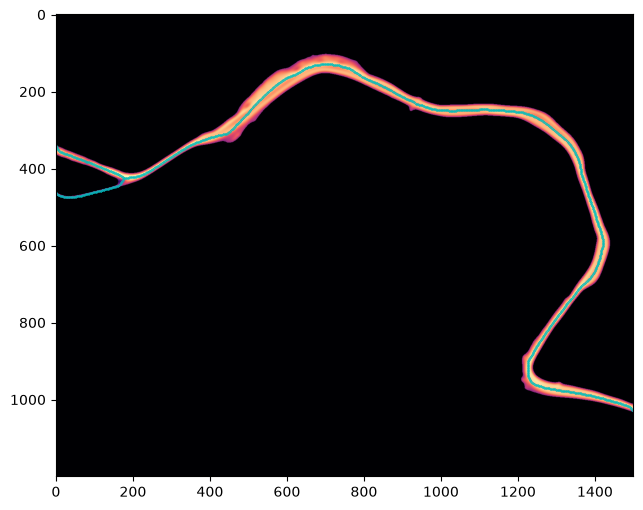

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import gaussian
from skimage.morphology import skeletonize, remove_small_objects, closing, disk
from skimage import measure
from skimage.filters import frangi
from scipy.ndimage import convolve, label



def prune_skeleton_spurs_smart(skeleton, heatmap, min_branch_length=60, max_iter=3):
    """
    智能骨架毛刺修剪：加入边界保护与热力值加权，防止误删源头主干
    :param skeleton: 二值骨架图
    :param heatmap: 对数压缩后的热力图底图 (用于评估支流热力高低)
    :param min_branch_length: 允许保留的末端分支最小长度 (调小至60，保护左上角短主干)
    """
    pruned = skeleton.copy().astype(bool)
    h, w = skeleton.shape
    
    # 8连通邻域卷积核，用于计算当前像素周边的邻居数量
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]])
                       
    for iteration in range(max_iter):
        # 1. 计算每个骨架像素的邻居数
        neighbors = convolve(pruned.astype(np.uint8), kernel, mode='constant')
        
        # 2. 识别端点 (邻居为1) 和 交叉点 (邻居>2)
        endpoints = pruned & (neighbors == 1)
        intersections = pruned & (neighbors > 2)
        
        # 如果当前骨架已经没有任何端点 (纯环状)，直接结束
        if not np.any(endpoints):
            break
        
        # 3. 抠除交叉点，打断骨架，形成独立的线段
        segments = pruned & ~intersections
        
        # 4. 对独立线段进行连通域标记
        labeled_segments, num_features = label(segments, structure=np.ones((3,3)))
        
        branches_removed = False
        
        # 5. 查找并删除过短的末端分支
        for i in range(1, num_features + 1):
            mask = (labeled_segments == i)
            
            # 核心判断 1：该线段是否包含端点 (是否为末端分支)
            is_endpoint_branch = np.any(mask & endpoints)
            
            if is_endpoint_branch:
                # 核心判断 2【边界保护】：如果这个分支触碰了图像边缘（四周各留5个像素的安全区），绝对不删！
                # 这样能保证河流源头（左上角边缘）和出口完美延伸到最外围。
                touches_boundary = np.any(mask[0:5, :]) or np.any(mask[h-5:h, :]) or \
                                   np.any(mask[:, 0:5]) or np.any(mask[:, w-5:w])
                
                if touches_boundary:
                    continue # 触碰边界的末端分支直接放过，保留！
                
                # 核心判断 3【热力加权】：计算该分支上的平均热力值
                # 如果虽然短，但热力值极高（说明是高热力支流），也可以选择保留
                branch_mean_heat = np.mean(heatmap[mask])
                
                # 综合判断：长度小于阈值 且 热力没有特别突出的，才判定为毛刺删除
                length = np.sum(mask)
                if length < min_branch_length:
                    pruned[mask] = False
                    branches_removed = True
                    
        if not branches_removed:
            break
            
        pruned = skeletonize(pruned)
        
    return pruned


def extract_thermal_ridge(heatmap):
    """
    提取带分叉的高动态范围热力图脊线
    :param heatmap: 2D numpy array (3500 x 4000)
    :return: skeleton (二值骨架图), coords (脊线坐标)
    """
    
    # ---------------------------------------------------------
    # 第一步：数据预处理 (对数变换与平滑)
    # ---------------------------------------------------------
    # 1. 使用 log1p (即 log(1+x)) 压缩极端的动态范围
    print("1. 正在进行对数压缩与高斯平滑...")
    heatmap_log = np.log1p(heatmap)
    
    # 2. 高斯平滑
    # 河流宽20-30像素，sigma取3-5较为合适，可消除局部噪点，防止骨架毛刺
    smoothed = gaussian(heatmap_log, sigma=4.0)
    
    # ridge_enhanced = frangi(heatmap_log, sigmas=range(5, 15, 2), black_ridges=False)
    # ---------------------------------------------------------
    # 第二步：自适应二值化分割
    # ---------------------------------------------------------
    print("2. 正在进行百分位阈值分割...")
    # 河流面积约占总面积的 0.7%，所以取 99.0% ~ 99.3% 的分位数作为阈值
    # 你可以根据实际二值化效果微调这个参数 (例如改成 99.0)
    threshold_val = np.percentile(smoothed, 95.5)
    # threshold_max = np.percentile(smoothed, 99.5)
    # threshold_val = np.percentile(ridge_enhanced, 99.2)
    
    binary_mask = smoothed > threshold_val
    
    # ---------------------------------------------------------
    # 第三步：形态学清理
    # ---------------------------------------------------------
    print("3. 正在进行形态学清理...")
    # 闭运算：填补河流内部的黑色小孔（半径取河流宽度的一半，如10）
    cleaned_mask = closing(binary_mask, disk(10))
    
    # 移除孤立的热力噪点团块（假设面积小于5000像素的都不是主干流）
    cleaned_mask = remove_small_objects(cleaned_mask, min_size=5000)
    
    # ---------------------------------------------------------
    # 第四步：骨架化提取带分叉的脊线
    # ---------------------------------------------------------
    print("4. 正在提取拓扑骨架...")
    # skeletonize 会剥离边界，留下单像素宽的连通线，完美保留分叉
    skeleton = skeletonize(cleaned_mask)
    
    # pruned_skeleton = prune_skeleton_spurs(skeleton, min_branch_length=200, max_iter=3)
    pruned_skeleton = prune_skeleton_spurs_smart(skeleton, heatmap_log, min_branch_length=180, max_iter=5)
    
    
    # 获取脊线的 (y, x) 坐标
    y_coords, x_coords = np.where(pruned_skeleton)
    coords = np.column_stack((x_coords, y_coords))
    
    print(f"提取完成！共提取出 {len(coords)} 个脊线像素点。")
    return pruned_skeleton, coords, smoothed, cleaned_mask

# =============================================================
# 使用示例与可视化展示
# =============================================================
if __name__ == "__main__":
    # 【模拟数据生成】 - 供测试用，实际使用时请替换为你的 3500x4000 heatmap 数组
    # heatmap = np.load('your_data.npy')
    heatmap = np.load('heatmap_small_filter.npy')
    heatmap = np.flip(heatmap, axis=0)
    print(heatmap.shape)
    
    # 实际调用函数
    skeleton, ridge_coords, smoothed, cleaned_mask = extract_thermal_ridge(heatmap)
    
    plt.figure(figsize=(8, 6))
    # plt.imshow(skeleton[900:1100, 1200:1400], cmap='magma')
    plt.imshow(skeleton, cmap='magma')
    plt.show()
    
    
    y_coords, x_coords = np.where(skeleton)
    coords = np.column_stack((x_coords, y_coords))
    # plt.plot(coords[:, 0]+3050, coords[:, 1]+1650, 'c.', markersize=0.5)  # 注意坐标偏移
    plt.figure(figsize=(8, 6))
    plt.imshow(cleaned_mask*smoothed, cmap='magma')
    plt.plot(coords[:, 0], coords[:, 1], 'c.', markersize=0.5)  # 注意坐标偏移
    
    plt.show()
    
    # heatmap_log = np.log1p(heatmap)
    # # 以下为绘图验证代码（在你有真实数据时运行）
    # fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # axes[0].imshow(heatmap_log[1600:2300, 2800:3300], cmap='magma')
    # axes[0].set_title('1. Log Transformed')
    
    # axes[1].imshow(cleaned_mask, cmap='gray')
    # axes[1].set_title('2. Binary Mask')
    
    # # 将骨架叠加在平滑后的热力图上
    # axes[2].imshow(smoothed, cmap='magma')
    # axes[2].plot(ridge_coords[:, 0], ridge_coords[:, 1], 'c.', markersize=0.1)
    # axes[2].set_title('3. Ridge on Smoothed Heatmap')
    
    # # 局部放大看分叉细节
    # axes[3].imshow(skeleton, cmap='gray')
    # axes[3].set_title('4. Extracted Skeleton')
    
    # plt.tight_layout()
    # plt.show()
    
    # # plt.figure(figsize=(16, 14))
    # # plt.imshow(cleaned_mask, cmap='magma')
    # # plt.show()
    
    # # plt.figure(figsize=(16, 14))
    # # plt.imshow(heatmap_log[1600:2300, 2800:3300], cmap='magma')
    # # plt.show()
    
    # plt.figure(figsize=(14, 14))
    # plt.imshow(smoothed[1650:1800, 3050:3200], cmap='magma')
    
    # subarea = skeleton[1650:1800, 3050:3200]
    # y_coords, x_coords = np.where(subarea)
    # coords = np.column_stack((x_coords, y_coords))
    # # plt.plot(coords[:, 0]+3050, coords[:, 1]+1650, 'c.', markersize=0.5)  # 注意坐标偏移
    # plt.plot(coords[:, 0], coords[:, 1], 'c.', markersize=3)  # 注意坐标偏移
    
    # # plt.imshow(skeleton[1650:1750, 3050:3150], cmap='gray')
    # plt.show()

In [7]:
# plt.figure(figsize=(16, 14))
# plt.imshow(skeleton, cmap='gray')
# plt.show()

# skeleton, ridge_coords, smoothed, cleaned_mask
np.save('./skeleton_small_filter.npy', skeleton)
np.save('./ridge_coords_small_filter.npy', ridge_coords)
np.save('./smoothed_small_filter.npy', smoothed)
np.save('./cleaned_mask_small_filter.npy', cleaned_mask)




发现 3 个交汇点，正在切断图以提取独立线段...
Row number: 1200
Row number: 1200
Row number: 1200
213.8944443027286
[340   0]
[424 175]
2414.223663640851
[425 178]
[1029 1498]
204.36753236814727
[427 175]
[462   0]


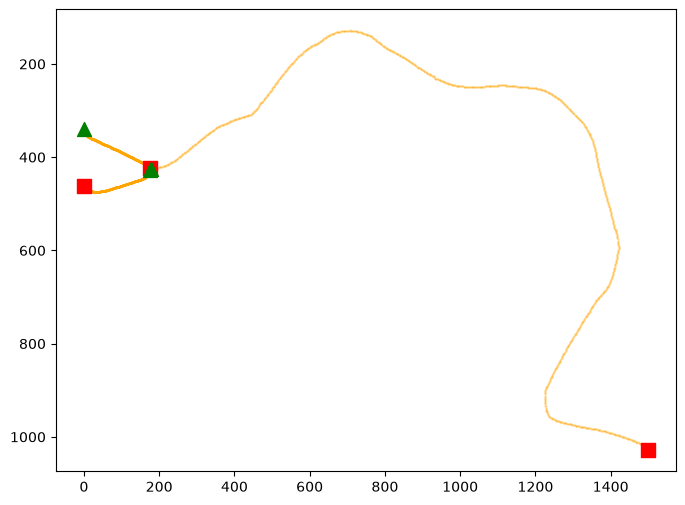

In [8]:
import numpy as np
import networkx as nx
from scipy.interpolate import splprep, splev
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, MultiPoint, Point, LineString, MultiPolygon

def build_spline_network(binary_skeleton, flow_vector=(1, 0), smoothing=5.0):
    """
    针对包含分叉/合并拓扑的骨架，建立按长度参数化的样条方程组
    
    :param binary_skeleton: 连续无断裂的单像素二值骨架图
    :param flow_vector: 宏观河流流向，用于统一各分支的方向，如 (dx, dy)
    :param smoothing: 样条拟合的平滑系数 (s值)
    :return: 包含所有独立样条参数方程的字典
    """
    # 1. 提取点并建立图
    y_idx, x_idx = np.where(binary_skeleton > 0)
    point_set = set(zip(y_idx, x_idx))
    
    G = nx.Graph()
    for y, x in point_set:
        for dy, dx in [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]:
            nb = (y + dy, x + dx)
            if nb in point_set:
                G.add_edge((y, x), nb)
                
    # 2. 寻找交汇点 (度数 >= 3) 并切断图
    junctions = [n for n, d in G.degree() if d >= 3]
    print(f"发现 {len(junctions)} 个交汇点，正在切断图以提取独立线段...")
    
    G_segmented = G.copy()
    G_segmented.remove_nodes_from(junctions)
    
    # 3. 提取所有无分叉的独立线段
    segments = list(nx.connected_components(G_segmented))
    
    spline_network = {}
    flow_vector = np.array(flow_vector)
    
    for seg_id, seg_nodes in enumerate(segments):
        if len(seg_nodes) < 5: 
            continue # 忽略极短的拓扑噪声
            
        # a. 对线段内的点进行空间排序 (重新建子图并寻找两个端点)
        sub_G = G.subgraph(seg_nodes)
        sub_endpoints = [n for n, d in sub_G.degree() if d == 1]
        
        # 如果是环形 (无端点)，暂不处理；正常航道必有两端
        if not sub_endpoints: continue
            
        start_node = sub_endpoints[0]
        # 使用最短路径即可得到严格有序的点序列
        ordered_path = nx.shortest_path(sub_G, source=start_node, target=sub_endpoints[-1])
        
        # b. 流向对齐校验
        path_coords = np.array(ordered_path)
        seg_vector = path_coords[-1] - path_coords[0] # 线段的宏观方向
        if np.dot(seg_vector, flow_vector) < 0:
            path_coords = path_coords[::-1] # 逆流，翻转顺序
            
        # c. 计算累积弧长参数 s
        diffs = np.diff(path_coords, axis=0)
        segment_lengths = np.linalg.norm(diffs, axis=1)
        s_params = np.insert(np.cumsum(segment_lengths), 0, 0)
        
        # new_y = row_num-1-y
        row_num = binary_skeleton.shape[0]
        print(f"Row number: {row_num}")
        new_y = row_num - 1 - path_coords[:, 0]
        
        phys_coords = np.column_stack((path_coords[:, 1]*10, new_y*10))  # 转换为 (x, y) 坐标
        # d. 三次样条拟合 (B-Spline)
        x_coords = path_coords[:, 1]
        y_coords = path_coords[:, 0]
        
        # splprep 自动处理参数化拟合
        # u 是归一化的参数 [0, 1]，tck 是样条的节点和系数
        tck, u = splprep([x_coords, y_coords], u=s_params, s=smoothing, k=3)
        
        spline_network[f"segment_{seg_id}"] = {
            "tck": tck,                  # 样条方程核心参数
            "length": s_params[-1],      # 该分支的物理总长度
            "start_pt": path_coords[0],  # 锚点
            "end_pt": path_coords[-1],
            "centerline_geom":LineString(phys_coords)
        }
        
    return spline_network

# 使用方法：
# flow_dir = (1, 0.5) # 假设河流整体向右下流
# splines = build_spline_network(continuous_skeleton, flow_vector=flow_dir)




def plot_spline_segment(segment_data, num_points=500):
    """
    基于 tck 参数方程和总长度，绘制单段航道样条曲线
    
    :param segment_data: 字典，包含 'tck', 'length', 'start_pt', 'end_pt'
    :param num_points: 想要在曲线上采样的点数（决定曲线的平滑度）
    """
    tck = segment_data["tck"]
    total_length = segment_data["length"]
    start_pt = segment_data["start_pt"]
    end_pt = segment_data["end_pt"]
    
    # 1. 构建连续的弧长参数 s
    # 在 [0, total_length] 区间内均匀生成 num_points 个参数点
    s_eval = np.linspace(0, total_length, num_points)
    
    # 2. 将参数 s 代入 tck 方程，求出对应的离散 x, y 坐标
    # splev 会自动解析 tck 并返回 (x_array, y_array)
    coords_eval = splev(s_eval, tck)
    x_eval = coords_eval[0]
    y_eval = coords_eval[1]
    
    return coords_eval
    # 3. 开始绘图
    # plt.figure(figsize=(10, 8))
    
    # # 画出连续的拟合曲线
    # plt.plot(x_eval, y_eval, color='blue', linewidth=2, label=f"Spline Curve (Len: {total_length:.1f})")
    
    # # 标出起点和终点，验证流向对齐是否成功
    # # 注意：我们之前的 start_pt 格式是 (y, x)，绘图时通常是 (x, y)
    # plt.scatter(start_pt[1], start_pt[0], color='green', s=100, marker='^', zorder=5, label='Start Node')
    # plt.scatter(end_pt[1], end_pt[0], color='red', s=100, marker='s', zorder=5, label='End Node')
    
    # # 如果你想看看均匀采样的点长什么样，可以把下面这行取消注释
    # # plt.scatter(x_eval, y_eval, color='orange', s=10, alpha=0.5, label='Sampled Points')
    
    # # 设置图像翻转 (如果是图像坐标系，原点在左上角，Y轴向下)
    # plt.gca().invert_yaxis() 
    
    # plt.title("Parametric Spline Trajectory Visualization")
    # plt.xlabel("X Coordinate")
    # plt.ylabel("Y Coordinate")
    # plt.legend()
    # plt.grid(True, linestyle='--', alpha=0.6)
    # plt.axis('equal') # 保证 X 轴和 Y 轴比例一致，不发生几何形变
    # plt.show()

# ==========================================
# 调用示例：
# ==========================================
# 假设你之前提取的字典叫 spline_network，想画出名为 'segment_0' 的分支
# target_segment = spline_network["segment_0"]
# plot_spline_segment(target_segment, num_points=1000)

if __name__ == '__main__':
    skeleton = np.load('./skeleton_small_filter.npy')
    spline_network = build_spline_network(skeleton)
    
    # total_coords = []
    plt.figure(figsize=(8, 6))
    for key in spline_network.keys():

        target_segment = spline_network[key]
        total_length = target_segment["length"]
        start_pt = target_segment["start_pt"]
        end_pt = target_segment["end_pt"]
        
        print(total_length)
        print(start_pt)
        print(end_pt)
        
        cordi = plot_spline_segment(target_segment, num_points=1000)
        # total_coords.append(cordi)
        x_eval = cordi[0]
        y_eval = cordi[1]

        # plt.plot(x_eval, y_eval, color='blue', linewidth=2, label=f"Spline Curve (Len: {total_length:.1f})")
   
        plt.scatter(start_pt[1], start_pt[0], color='green', s=100, marker='^', zorder=5, label='Start Node')
        plt.scatter(end_pt[1], end_pt[0], color='red', s=100, marker='s', zorder=5, label='End Node')
        plt.scatter(x_eval, y_eval, color='orange', s=0.2, alpha=0.5, label='Sampled Points')
        
        
    plt.gca().invert_yaxis() 
    plt.show()


In [9]:
import pickle
with open('./spline_network_filter.pkl', 'wb') as f:
    pickle.dump(spline_network, f)

22591427
3. 正在进行形态学清理...


C:\Users\Administrator\AppData\Local\Temp\ipykernel_47056\771134939.py:39: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  cleaned_mask = remove_small_objects(cleaned_mask, min_size=5000)


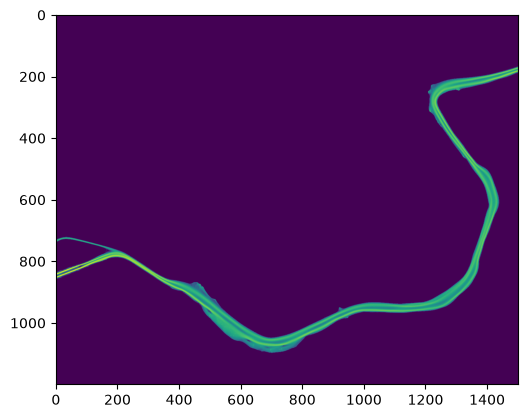

In [11]:
import numpy as np
from skimage.morphology import skeletonize, remove_small_objects, closing, disk
from skimage.filters import gaussian
import matplotlib.pyplot as plt

points = np.load('test_pts_filter.npy')
grid_shape = (1200, 1500)
chunk_size = 50000000
resolution = 10.0


grid_counts = np.zeros(grid_shape, dtype=np.float32)

H, W = grid_shape
total_pts = len(points)
print(total_pts)

for i in range(0, total_pts, chunk_size):
    chunk = points[i:i + chunk_size]
    pix_pts = chunk / resolution
    px = np.clip(pix_pts[:, 0], 0, W - 1).astype(int)
    py = np.clip(pix_pts[:, 1], 0, H - 1).astype(int)
    np.add.at(grid_counts, (py, px), 1.0)

log_map = np.log1p(grid_counts)
smoothed = gaussian(log_map, sigma=4.0)
threshold_val = np.percentile(smoothed, 95.5)

binary_mask = smoothed > threshold_val

# ---------------------------------------------------------
# 第三步：形态学清理
# ---------------------------------------------------------
print("3. 正在进行形态学清理...")
# 闭运算：填补河流内部的黑色小孔（半径取河流宽度的一半，如10）
cleaned_mask = closing(binary_mask, disk(10))

# 移除孤立的热力噪点团块（假设面积小于5000像素的都不是主干流）
cleaned_mask = remove_small_objects(cleaned_mask, min_size=5000)

grid_counts = cleaned_mask * grid_counts

np.save('heatmap_small_test_filter.npy', grid_counts)
plt.figure()
plt.imshow(np.log1p(grid_counts), cmap='viridis')
plt.show()


8.551787
length: 2424.2236636408506
start_pt: [426 174]
end_pt: [1030 1498]
new_ds: 8.00073816383119
s_eval: 4.000369081915595
s_eval: 12.001107245746786
s_eval: 20.001845409577975
s_eval: 28.00258357340917
s_eval: 36.003321737240356
s_eval: 44.00405990107154
s_eval: 52.00479806490274


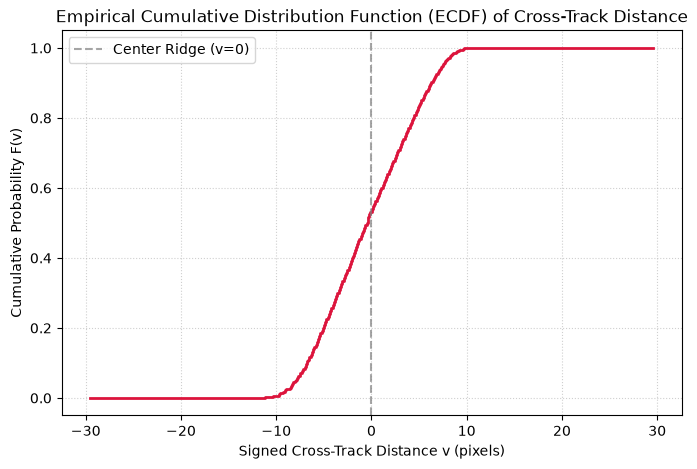

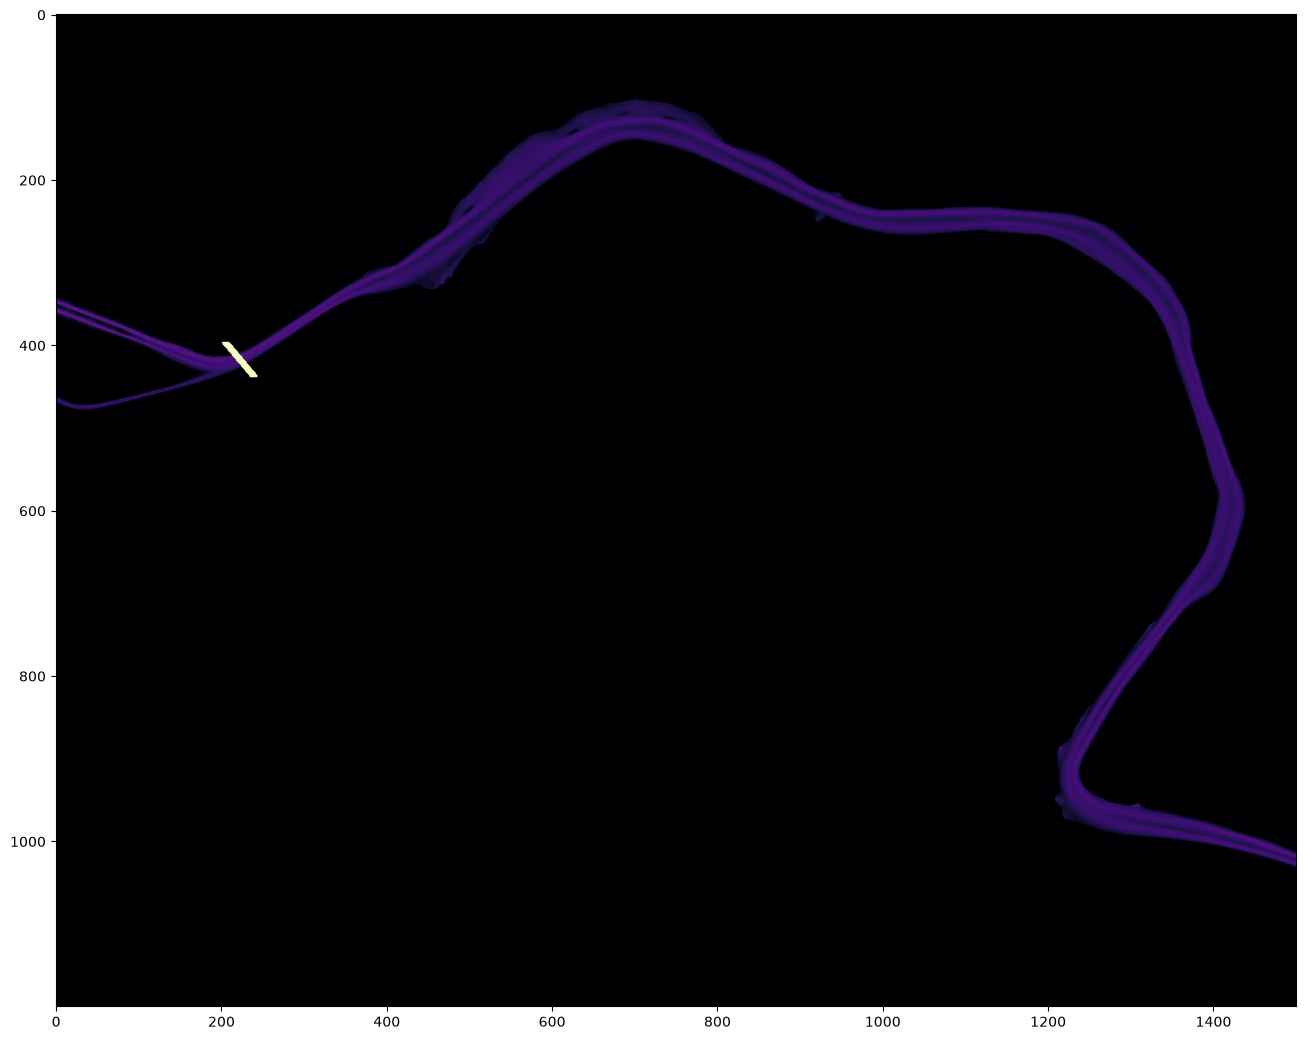

In [6]:
# import json
# f = open('./spline_network.json', 'w', encoding='utf-8')
# spline_network = json.dumps(spline_network, ensure_ascii=False)
# f.close()

from scipy.interpolate import splprep, splev
import numpy as np


import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import splev

def analyze_local_cross_track_ecdf(tck, s, heatmap, L=4.0, W=8.0, weighted=True):
    """
    计算脊线在弧长 s 处局部区域 T 内点的带符号跨轨距离及其经验累积分布函数 (ECDF)
    
    :param tck: scipy 三次样条方程参数 (t, c, k)
    :param s: 给定的弧长参数值 (0 <= s <= total_length)
    :param heatmap: 2D 热力图 numpy 矩阵，heatmap[y, x] 表示坐标 (x, y) 处的热力强度
    :param L: 管状区域 T 沿切线方向的总长度
    :param W: 管状区域 T 沿法线方向的半宽度 (总宽度为 2*W)
    :param weighted: True 时使用热力图像素值作为权重计算加权 ECDF，False 为标准 ECDF
    :return: 包含局部几何参数、跨轨距离及 ECDF 曲线数据的字典
    """
    # 1. 计算 s 处的中心点 P(s) 与一阶导数 P'(s)
    P = splev(s, tck, der=0)    # [x(s), y(s)]
    dP = splev(s, tck, der=1)   # [x'(s), y'(s)]
    
    x0, y0 = P[0], P[1]
    dx, dy = dP[0], dP[1]
    
    # 2. 计算单位切向量 T 与单位法向量 N
    norm_t = np.hypot(dx, dy)
    if norm_t == 0:
        raise ValueError(f"弧长 s={s} 处的导数为 0，无法确定切线方向。")
    
    # 将切向量归一化为单位向量
    Tx, Ty = dx / norm_t, dy / norm_t
    # 逆时针旋转 90 度作为法向
    Nx, Ny = -Ty, Tx  
    
    # 3. 建立局部 ROI 包围盒以加速像素提取
    max_r = np.sqrt(L**2 + W**2)
    H, W = heatmap.shape
    
    min_x = int(np.clip(np.floor(x0 - max_r), 0, W - 1))
    max_x = int(np.clip(np.ceil(x0 + max_r), 0, W - 1))
    min_y = int(np.clip(np.floor(y0 - max_r), 0, H - 1))
    max_y = int(np.clip(np.ceil(y0 + max_r), 0, H - 1))
    
    # 4. 生成 ROI 区域内的网格像素坐标
    grid_x, grid_y = np.meshgrid(np.arange(min_x, max_x + 1), np.arange(min_y, max_y + 1))
    
    # 计算相对向量 V = Q - P(s)
    Vx = grid_x - x0
    Vy = grid_y - y0
    
    # 投影到切线与法线方向
    u = Vx * Tx + Vy * Ty  # 沿轨距离 (along-track)
    v = Vx * Nx + Vy * Ny  # 跨轨距离 (cross-track, 带符号)
    
    # 5. 筛选落在管状区域 T 内的点 (|u| <= L 且 |v| <= W)
    inside_mask = (np.abs(u) <= L) & (np.abs(v) <= W)
    
    # valid_v是1维数组，包含所有落在区域 T 内的跨轨距离
    valid_v = v[inside_mask]
    
    # grid_y[inside_mask]和grid_x[inside_mask]是对应的像素坐标，用于从热力图中提取权重
    valid_weights = heatmap[grid_y[inside_mask], grid_x[inside_mask]]
    
    if len(valid_v) == 0:
        raise ValueError(f"在 s={s} 处的区域 T 内未检测到任何像素点，请适当调大 L 或 W。")
        
    # 6. 计算经验累积分布函数 (ECDF)
    sort_idx = np.argsort(valid_v)
    sorted_v = valid_v[sort_idx]
    sorted_weights = valid_weights[sort_idx]
    
    if weighted and np.sum(sorted_weights) > 0:
        # 基于热力图权重的累积概率分布
        cum_weights = np.cumsum(sorted_weights)
        ecdf_y = cum_weights / cum_weights[-1]
    else:
        # 离散点的标准未加权 ECDF
        ecdf_y = np.arange(1, len(sorted_v) + 1) / len(sorted_v)
        
    return {
        "center": (x0, y0),
        "tangent": (Tx, Ty),
        "normal": (Nx, Ny),
        "cross_track_distances": sorted_v,
        "ecdf_x": sorted_v,
        "ecdf_y": ecdf_y,
        "weights": sorted_weights,
        "inside_coords": (grid_x[inside_mask], grid_y[inside_mask])
    }

def plot_ecdf_results(analysis_res):
    """ 绘制带符号跨轨距离的 ECDF 曲线 """
    plt.figure(figsize=(8, 5))
    plt.step(analysis_res["ecdf_x"], analysis_res["ecdf_y"], where='post', color='crimson', linewidth=2)
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Center Ridge (v=0)')
    plt.title("Empirical Cumulative Distribution Function (ECDF) of Cross-Track Distance")
    plt.xlabel("Signed Cross-Track Distance v (pixels)")
    plt.ylabel("Cumulative Probability F(v)")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()

# ==========================================
# 使用示例：
# ==========================================
# 假设已获取某段样条方程 tck，在弧长 s=150.0 处提取 L=50, W=25 的区域
# res = analyze_local_cross_track_ecdf(target_segment["tck"], s=150.0, heatmap=raw_heatmap, L=50.0, W=25.0)
# plot_ecdf_results(res)




L = 4
W = 15
weighted = True
# heatmap = np.load('./heatmap_small.npy')
heatmap = np.load('./heatmap_small_test_filter.npy')

heatmap = np.flip(heatmap, axis=0)
heatmap = np.log1p(heatmap)
print(heatmap.max())

for key in spline_network.keys():
    segment = spline_network[key]
    length = segment["length"]
    print('length:', length)
    print('start_pt:', segment["start_pt"])
    print('end_pt:', segment["end_pt"])
    
    tck = segment["tck"]
    
    ds = 2*L
    
    sub_segment_num = int(length // ds)
    # res = length - ds * sub_segment_num
    new_ds = length/sub_segment_num
    print('new_ds:', new_ds)
    
    s = []
    for i in range(sub_segment_num):
        s.append(new_ds * i+new_ds/2.0)
        
    # s.append(length - res/2.0)
    
    count = 0
    for s_eval in s:
        count += 1
        print('s_eval:', s_eval)
        
        analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=new_ds/2.0, W=20.0, weighted=True)
        # if count<len(s):
        #     analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=4.0, W=8.0, weighted=True)

        # else:
        #     analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=res/2.0, W=8.0, weighted=True)
        
        # plot_ecdf_results(analysis_res)
        # print(analysis_res['inside_coords'])
        
        if count==7:
            plot_ecdf_results(analysis_res)
            inside_x, inside_y = analysis_res['inside_coords']
            for i in range(len(inside_x)):
                x = inside_x[i]
                y = inside_y[i]
                
                # print('x:', x, 'y:', y)
                heatmap[y, x] = 30
            break    
    
    break
plt.figure(figsize=(16, 14))
# plt.imshow(heatmap[900:1000, 850:950], cmap='magma')
plt.imshow(heatmap, cmap='magma')
plt.show()


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def smooth_fairway_boundaries(s_grid, left_pts, right_pts, centers, normals, window_length=11, polyorder=2):
    """
    基于 1D 跨轨距离 signal 进行 Savitzky-Golay 平滑并重构 2D 航道边界
    
    :param s_grid: 弧长参数数组 (S,)
    :param left_pts: 原始左边界像素坐标数组 (S, 2)
    :param right_pts: 原始右边界像素坐标数组 (S, 2)
    :param centers: 脊线中心点坐标数组 (S, 2)
    :param normals: 脊线单位法向量数组 (S, 2)
    :param window_length: SG 滤波器窗口大小 (必须为大于 polyorder 的奇数，越大越平滑)
    :param polyorder: 多项式拟合阶数 (通常设为 2 或 3)
    :return: 平滑后的 (left_smooth_2d, right_smooth_2d)
    """
    
    # 强制将输入转换为 NumPy 2D 数组 (N, 2)，兼容 tuple 和 list 深度输入
    s_grid = np.asarray(s_grid)
    left_pts = np.asarray(left_pts)
    right_pts = np.asarray(right_pts)
    centers = np.asarray(centers)
    normals = np.asarray(normals)
    
    # 1. 反算原始的 1D 跨轨距离 v_left 和 v_right
    # v = (Point - Center) · Normal
    vec_left = left_pts - centers
    vec_right = right_pts - centers
    
    v_left = np.sum(vec_left * normals, axis=1)
    v_right = np.sum(vec_right * normals, axis=1)
    
    # 2. 动态调整窗口大小 (确保为奇数且不超过数据长度)
    n_pts = len(s_grid)
    win_len = min(window_length, n_pts if n_pts % 2 != 0 else n_pts - 1)
    if win_len <= polyorder:
        win_len = polyorder + 2 if (polyorder + 2) % 2 != 0 else polyorder + 3
        
    # 3. 使用 Savitzky-Golay 滤波器平滑 1D 标量序列 v(s)
    v_left_smooth = savgol_filter(v_left, window_length=win_len, polyorder=polyorder)
    v_right_smooth = savgol_filter(v_right, window_length=win_len, polyorder=polyorder)
    
    # 4. 根据平滑后的 v 值重构 2D 边界像素坐标
    # Point_smooth = Center + v_smooth * Normal
    left_smooth_2d = centers + v_left_smooth[:, np.newaxis] * normals
    right_smooth_2d = centers + v_right_smooth[:, np.newaxis] * normals
    
    return left_smooth_2d, right_smooth_2d

# def plot_boundary_smoothing_demo(centers, left_raw, right_raw, left_smooth, right_smooth):
#     """ 可视化平滑前后对比图 """
#     plt.figure(figsize=(10, 8))
    
#     # 绘制脊线
#     plt.plot(centers[:, 0], centers[:, 1], 'k--', label='Center Ridge', alpha=0.7)
    
#     # 绘制带尖刺的原始边界
#     plt.plot(left_raw[:, 0], left_raw[:, 1], color='red', alpha=0.3, label='Raw Left (Spiky)')
#     plt.plot(right_raw[:, 0], right_raw[:, 1], color='green', alpha=0.3, label='Raw Right (Spiky)')
    
#     # 绘制 SG 平滑后的光滑边界
#     plt.plot(left_smooth[:, 0], left_smooth[:, 1], color='darkred', linewidth=2, label='Smoothed Left Boundary')
#     plt.plot(right_smooth[:, 0], right_smooth[:, 1], color='darkgreen', linewidth=2, label='Smoothed Right Boundary')
    
#     plt.gca().invert_yaxis()  # 像素坐标系 Y 轴向下
#     plt.axis('equal')
#     plt.title("Fairway Boundary Smoothing via 1D Cross-Track SG Filter")
#     plt.xlabel("Pixel X")
#     plt.ylabel("Pixel Y")
#     plt.legend()
#     plt.grid(True, linestyle=':', alpha=0.6)
#     plt.show()

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt, savgol_filter
from scipy.interpolate import splprep, splev

def ultimate_smooth_fairway_boundaries(s_grid, centers, normals, left_pts, right_pts,
                                      med_kernel=5, sg_window=15, sg_poly=2, spline_s=10.0):
    """
    终极平滑方案：中值滤波去噪 + 法线角度平滑 + 2D B-Spline 参数重拟合
    
    :param s_grid: 弧长网格 (S,)
    :param centers: 脊线中心点 (S, 2)
    :param normals: 脊线原始单位法向量 (S, 2)
    :param left_pts: 原始左边界像素坐标数组 (S, 2)
    :param right_pts: 原始右边界像素坐标数组 (S, 2)
    :param v_left_raw: 原始 1D 左跨轨距离数组 (S,)
    :param v_right_raw: 原始 1D 右跨轨距离数组 (S,)
    :param med_kernel: 中值滤波核大小 (奇数)，用于直接剔除 ECDF 离群野点
    :param sg_window: SG 滤波器窗口 (奇数)
    :param sg_poly: SG 多项式阶数
    :param spline_s: 2D B-Spline 的平滑因子 (越大多项式越平滑，剔除微小折线)
    """
    s_grid = np.asarray(s_grid)
    centers = np.asarray(centers)
    normals = np.asarray(normals)
    
    # 0. 反算原始的 1D 跨轨距离 v_left 和 v_right
    # v = (Point - Center) · Normal
    vec_left = left_pts - centers
    vec_right = right_pts - centers
    
    v_left_raw = np.sum(vec_left * normals, axis=1)
    v_right_raw = np.sum(vec_right * normals, axis=1)
    
    # -------------------------------------------------------------------------
    # 1. 第一击：平滑法线角度 $\theta(s)$，解决上下边界同步突折的根本问题
    # -------------------------------------------------------------------------
    # 将法向量转化为连续角度 (使用 unwrap 解决 -pi 到 pi 的跳跃)
    angles = np.arctan2(normals[:, 1], normals[:, 0])
    angles_unwrapped = np.unwrap(angles)
    
    # 对角度进行平滑，确保法向平稳旋转
    angles_smooth = savgol_filter(angles_unwrapped, window_length=sg_window, polyorder=sg_poly)
    
    # 重构平滑后的单位法向量
    normals_smooth = np.column_stack([np.cos(angles_smooth), np.sin(angles_smooth)])
    
    # -------------------------------------------------------------------------
    # 2. 第二击：1D 信号预处理 (中值滤波去野点 + SG 滤波)
    # -------------------------------------------------------------------------
    def smooth_1d_signal(v_raw):
        # 先用中值滤波瞬间杀掉单点野点 (Outlier)
        v_med = medfilt(v_raw, kernel_size=med_kernel)
        # 再用 SG 滤波做平滑
        return savgol_filter(v_med, window_length=sg_window, polyorder=sg_poly)
        
    v_left_sm = smooth_1d_signal(v_left_raw)
    v_right_sm = smooth_1d_signal(v_right_raw)
    
    # 初步合成 2D 点集
    left_2d_raw = centers + v_left_sm[:, np.newaxis] * normals_smooth
    right_2d_raw = centers + v_right_sm[:, np.newaxis] * normals_smooth
    
    # -------------------------------------------------------------------------
    # 3. 第三击：2D 几何空间 B-Spline 参数化重拟合 (彻底消除 Z 字形打结)
    # -------------------------------------------------------------------------
    def re_spline_2d(pts_2d, smoothing):
        # 移除空间距离过近的重叠点 (防止 splprep 报错)
        dists = np.sqrt(np.sum(np.diff(pts_2d, axis=0)**2, axis=1))
        keep_mask = np.insert(dists > 1e-3, 0, True)
        clean_pts = pts_2d[keep_mask]
        
        if len(clean_pts) < 4:
            return pts_2d
            
        x, y = clean_pts[:, 0], clean_pts[:, 1]
        
        # 参数化 2D 样条拟合，s 参量控制平滑度
        tck, u = splprep([x, y], s=smoothing, k=3)
        
        # 按照原点数重新等间距采样，生成极度顺滑的曲线
        u_fine = np.linspace(0, 1, len(pts_2d))
        x_smooth, y_smooth = splev(u_fine, tck)
        return np.column_stack([x_smooth, y_smooth])

    left_2d_final = re_spline_2d(left_2d_raw, smoothing=spline_s)
    right_2d_final = re_spline_2d(right_2d_raw, smoothing=spline_s)
    
    return left_2d_final, right_2d_final

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def compute_fairway_confidence_boundaries(analysis_res, confidence_level=0.60):
    """
    基于局部管状区域的 ECDF 输出，计算指定置信度水平的航道跨轨范围及全局图像坐标
    
    :param analysis_res: analyze_local_cross_track_ecdf 函数输出的字典
    :param confidence_level: 置信度水平 (0 < confidence_level < 1)，如 0.60 代表 60%
    :return: 包含三种策略下跨轨距离区间及对应全局 (X, Y) 坐标的字典
    """
    ecdf_x = np.array(analysis_res["ecdf_x"]) # 排序后的跨轨距离 v
    ecdf_y = np.array(analysis_res["ecdf_y"]) # 对应的累积概率 CDF(v)
    
    x0, y0 = analysis_res["center"]
    Nx, Ny = analysis_res["normal"]
    
    p = confidence_level
    if not (0 < p < 1):
        raise ValueError("置信度水平 confidence_level 必须在 (0, 1) 区间内。")
        
    results = {}

    # =========================================================================
    # 策略 1: 等尾分位数对称包络 (Equal-tailed Quantile Interval)
    # =========================================================================
    p_low = (1.0 - p) / 2.0
    p_high = 1.0 - p_low
    
    v_min_eq = np.interp(p_low, ecdf_y, ecdf_x)
    v_max_eq = np.interp(p_high, ecdf_y, ecdf_x)
    
    results["equal_tailed"] = {
        "v_range": (v_min_eq, v_max_eq),
        "width": v_max_eq - v_min_eq,
        'center': (x0, y0),
        "pt_min": (x0 + v_min_eq * Nx, y0 + v_min_eq * Ny),
        "pt_max": (x0 + v_max_eq * Nx, y0 + v_max_eq * Ny),
        'normal': (Nx, Ny)
    }

    # =========================================================================
    # 策略 2: 基于脊线 v=0 的零点对称包络 (Zero-Centered Symmetric Interval)
    # =========================================================================
    # 计算绝对距离 |v| 的累积概率分布
    abs_v = np.abs(ecdf_x)
    sort_abs_idx = np.argsort(abs_v)
    sorted_abs_v = abs_v[sort_abs_idx]
    
    # 重新计算绝对距离的加权/非加权 ECDF
    weights = np.array(analysis_res["weights"])[sort_abs_idx]
    if np.sum(weights) > 0:
        cum_abs_y = np.cumsum(weights) / np.cumsum(weights)[-1]
    else:
        cum_abs_y = np.arange(1, len(sorted_abs_v) + 1) / len(sorted_abs_v)
        
    r_sym = np.interp(p, cum_abs_y, sorted_abs_v)
    
    results["zero_symmetric"] = {
        "v_range": (-r_sym, r_sym),
        "width": 2 * r_sym,
        'center': (x0, y0),
        "pt_min": (x0 - r_sym * Nx, y0 - r_sym * Ny),
        "pt_max": (x0 + r_sym * Nx, y0 + r_sym * Ny),
        'normal': (Nx, Ny)
    }

    # =========================================================================
    # 策略 3: 非对称最小宽度包络 (Asymmetric / Highest Density Interval - HDI)
    # =========================================================================
    # 向量化寻找所有满足 ΔCDF >= p 的 index 组合中，Δv 最小的一组
    j_indices = np.searchsorted(ecdf_y, ecdf_y + p, side='left')
    valid_mask = j_indices < len(ecdf_y)
    
    if np.any(valid_mask):
        valid_i = np.where(valid_mask)[0]
        valid_j = j_indices[valid_mask]
        
        widths = ecdf_x[valid_j] - ecdf_x[valid_i]
        best_idx = np.argmin(widths)
        
        v_min_asym = ecdf_x[valid_i[best_idx]]
        v_max_asym = ecdf_x[valid_j[best_idx]]
    else:
        # 退化边界情况
        v_min_asym, v_max_asym = ecdf_x[0], ecdf_x[-1]

    results["asymmetric_hdi"] = {
        "v_range": (v_min_asym, v_max_asym),
        "width": v_max_asym - v_min_asym,
        'center': (x0, y0),
        "pt_min": (x0 + v_min_asym * Nx, y0 + v_min_asym * Ny),
        "pt_max": (x0 + v_max_asym * Nx, y0 + v_max_asym * Ny),
        'normal': (Nx, Ny)
    }

    return results

def print_and_plot_boundaries(analysis_res, bounds_res, confidence_level=0.60):
    """ 输出包络数值并绘制 ECDF 置信区间示意图 """
    print(f"=== 弧长 s 处置信度为 {confidence_level*100:.0f}% 的航道范围计算结果 ===")
    for strategy_name, res in bounds_res.items():
        v_min, v_max = res["v_range"]
        print(f"[{strategy_name}]")
        print(f"  跨轨范围 (v): [{v_min:.2f}, {v_max:.2f}] 像素")
        print(f"  包络总物理宽度: {res['width']:.2f} 像素")
        print(f"  左界图像坐标: ({res['pt_max'][0]:.1f}, {res['pt_max'][1]:.1f})")
        print(f"  右界图像坐标: ({res['pt_min'][0]:.1f}, {res['pt_min'][1]:.1f})")
        print("-" * 50)
        
    # 可视化比较
    plt.figure(figsize=(9, 5))
    plt.step(analysis_res["ecdf_x"], analysis_res["ecdf_y"], color='gray', alpha=0.6, label='ECDF')
    
    # 画出 HDI 非对称区间的包络线
    v_a_min, v_a_max = bounds_res["asymmetric_hdi"]["v_range"]
    plt.axvspan(v_a_min, v_a_max, color='orange', alpha=0.25, label=f'Asymmetric HDI ({confidence_level*100:.0f}%)')
    
    # 画出等尾对称区间的虚线
    v_e_min, v_e_max = bounds_res["equal_tailed"]["v_range"]
    plt.axvline(v_e_min, color='blue', linestyle='--', label=f'Equal-tailed Bounds')
    plt.axvline(v_e_max, color='blue', linestyle='--')
    
    # 画出零点对称包络
    v_z_min, v_z_max = bounds_res["zero_symmetric"]["v_range"]
    plt.axvline(v_z_min, color='cyan', linestyle='--', label=f'Zero-Symmetric Bounds')
    plt.axvline(v_z_max, color='cyan', linestyle='--')
    
    plt.axvline(0, color='red', linestyle=':', label='Center Ridge (v=0)')
    plt.title(f"Cross-Track ECDF with {confidence_level*100:.0f}% Confidence Intervals")
    plt.xlabel("Signed Cross-Track Distance v (pixels)")
    plt.ylabel("Cumulative Probability F(v)")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# ==========================================
# 调用示例：
# ==========================================
# 假设 analysis_res 为前面单点局部分析的输出结果
# if __name__ == '__main__':
    # bounds = compute_fairway_confidence_boundaries(analysis_res, confidence_level=0.70)
    # print_and_plot_boundaries(analysis_res, bounds, confidence_level=0.70)

12.170611
length: 2424.2236636408506
start_pt: [426 174]
end_pt: [1030 1498]
new_ds: 8.00073816383119
s_eval: 4.000369081915595
s_eval: 12.001107245746786
s_eval: 20.001845409577975
s_eval: 28.00258357340917
s_eval: 36.003321737240356
s_eval: 44.00405990107154
s_eval: 52.00479806490274
s_eval: 60.00553622873393
s_eval: 68.00627439256512
s_eval: 76.0070125563963
s_eval: 84.00775072022749
s_eval: 92.00848888405869
s_eval: 100.00922704788988
s_eval: 108.00996521172107
s_eval: 116.01070337555227
s_eval: 124.01144153938345
s_eval: 132.01217970321466
s_eval: 140.01291786704584
s_eval: 148.01365603087703
s_eval: 156.01439419470822
s_eval: 164.0151323585394
s_eval: 172.01587052237062
s_eval: 180.0166086862018
s_eval: 188.017346850033
s_eval: 196.01808501386418
s_eval: 204.01882317769537
s_eval: 212.01956134152655
s_eval: 220.02029950535774
s_eval: 228.02103766918896
s_eval: 236.02177583302014
s_eval: 244.02251399685133
s_eval: 252.02325216068252
s_eval: 260.0239903245137
s_eval: 268.0247284883

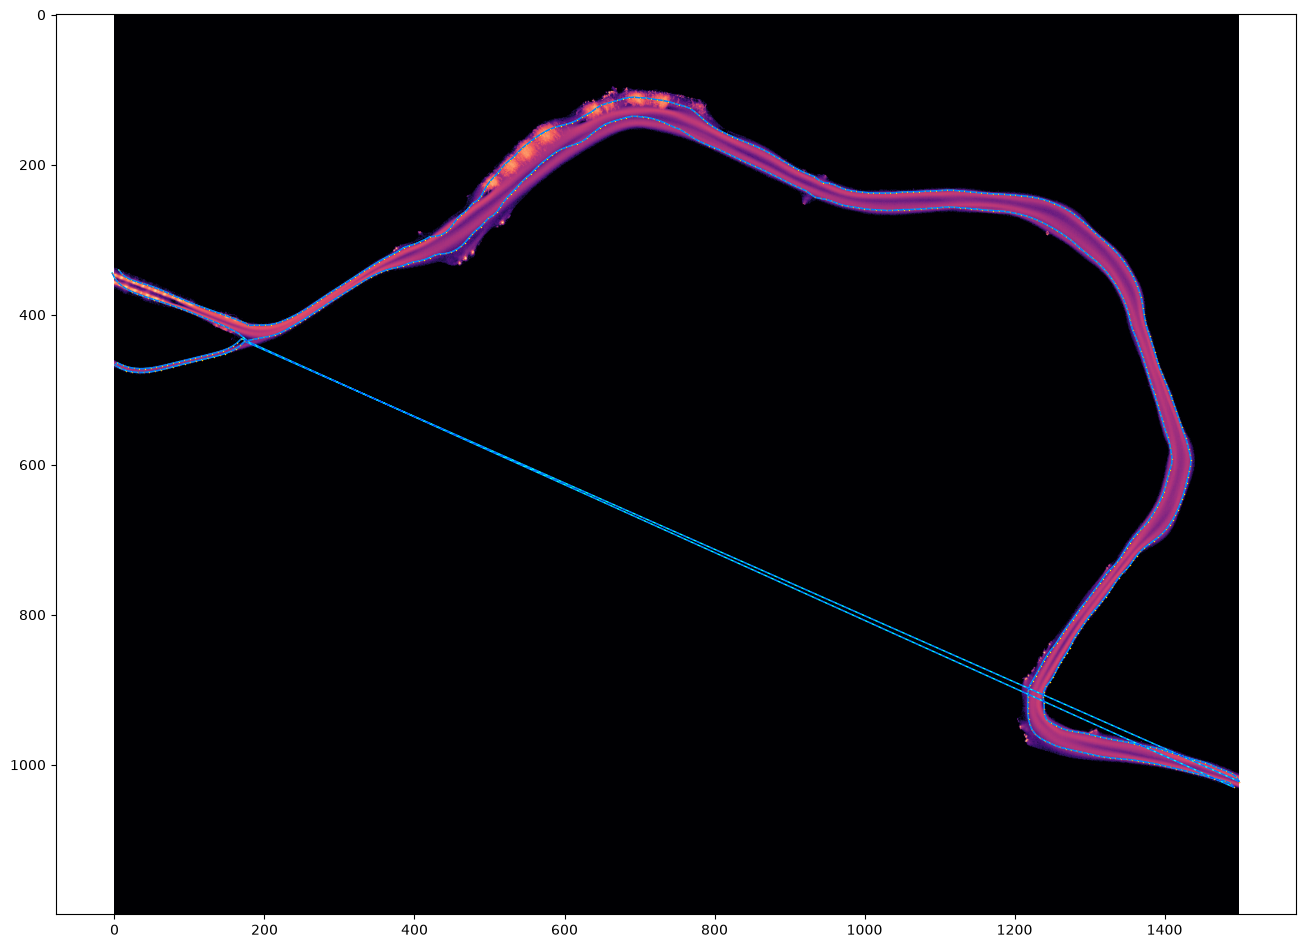

In [5]:
import json
from shapely.geometry import Polygon, LineString, Point
from shapely.ops import unary_union
from shapely import affinity
import numpy as np
import matplotlib.pyplot as plt
import pickle

L = 4
W = 15
weighted = True
# heatmap = np.load('./heatmap.npy')
# heatmap = np.flip(heatmap, axis=0)
# heatmap = np.log1p(heatmap)

heatmap = np.load('./heatmap_small_test.npy')
heatmap = np.flip(heatmap, axis=0)
heatmap = np.log1p(heatmap)

print(heatmap.max())

with open('./spline_network.pkl', 'rb') as f:   # 注意 'rb'，二进制读
        spline_network = pickle.load(f)


polygons = []
polygons_l = []
polygons_r = []

for key in spline_network.keys():
    segment = spline_network[key]
    length = segment["length"]
    print('length:', length)
    print('start_pt:', segment["start_pt"])
    print('end_pt:', segment["end_pt"])
    
    tck = segment["tck"]
    
    ds = 2*L
    
    sub_segment_num = int(length // ds)
    # res = length - ds * sub_segment_num
    new_ds = length/sub_segment_num
    print('new_ds:', new_ds)
    
    s = []
    for i in range(sub_segment_num):
        s.append(new_ds * i+new_ds/2.0)
        
    # s.append(length - res/2.0)
    
    count = 0
    one_polygon_l  = []
    one_polygon_r  = []
    one_polygon_c = []
    one_polygon_n = []
    for s_eval in s:
        count += 1
        print('s_eval:', s_eval)
        
        analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=new_ds/2.0, W=W, weighted=True)
        
        bounds = compute_fairway_confidence_boundaries(analysis_res, confidence_level=0.80)
        
        # {
        # "v_range": (-r_sym, r_sym),
        # "width": 2 * r_sym,
        # "pt_min": (x0 - r_sym * Nx, y0 - r_sym * Ny),
        # "pt_max": (x0 + r_sym * Nx, y0 + r_sym * Ny)
        # }
        bounds_asym = bounds["asymmetric_hdi"]
        # bounds_zero_sym = bounds["zero_symmetric"]
        
        # bounds_equ_tailed = bounds["equal_tailed"]
        

        # point_l = bounds_zero_sym["pt_max"]
        # point_r = bounds_zero_sym["pt_min"]
        # point_c = bounds_zero_sym["center"]
        # point_n = bounds_zero_sym["normal"]
        
        point_l = bounds_asym["pt_max"]
        point_r = bounds_asym["pt_min"]
        point_c = bounds_asym["center"]
        point_n = bounds_asym["normal"]
        
        one_polygon_l.append(point_l)
        one_polygon_r.append(point_r)
        one_polygon_c.append(point_c)
        one_polygon_n.append(point_n)
        
    polygons.append(one_polygon_l+one_polygon_r[::-1])
    # polygons_l.append(one_polygon_l)
    # polygons_r.append(one_polygon_r)
    
    # smooth_fairway_boundaries(s_grid, left_pts, right_pts, centers, normals, window_length=11, polyorder=2):
    """
    基于 1D 跨轨距离 signal 进行 Savitzky-Golay 平滑并重构 2D 航道边界
    
    :param s_grid: 弧长参数数组 (S,)
    :param left_pts: 原始左边界像素坐标数组 (S, 2)
    :param right_pts: 原始右边界像素坐标数组 (S, 2)
    :param centers: 脊线中心点坐标数组 (S, 2)
    :param normals: 脊线单位法向量数组 (S, 2)
    :param window_length: SG 滤波器窗口大小 (必须为大于 polyorder 的奇数，越大越平滑)
    :param polyorder: 多项式拟合阶数 (通常设为 2 或 3)
    :return: 平滑后的 (left_smooth_2d, right_smooth_2d)
    """
    # left_smooth_2d, right_smooth_2d = smooth_fairway_boundaries(s, one_polygon_l, one_polygon_r, one_polygon_c, one_polygon_n, window_length=21, polyorder=2)
    left_smooth_2d, right_smooth_2d = ultimate_smooth_fairway_boundaries(s, one_polygon_c, one_polygon_n, one_polygon_l, one_polygon_r, med_kernel=5, sg_window=15, sg_poly=2, spline_s=10.0)
    polygons_l.append(left_smooth_2d)
    polygons_r.append(right_smooth_2d)
   
# polygon = polygons[0]

# x = [p[0] for p in polygon]
# y = [p[1] for p in polygon]


# plt.figure(figsize=(16, 14))
# # plt.imshow(heatmap[900:1000, 850:950], cmap='magma')
# plt.imshow(heatmap, cmap='magma')

# # 在图像上绘制折线
# plt.plot(x, y, 'o-', markersize=1, linewidth=1, 
#         color='cyan', markerfacecolor='yellow', 
#         markeredgecolor='red', markeredgewidth=0.1)

# # 从第一个点连接到所有其他点
# first_point = polygon[0]
# for point in polygon[1:]:
#     plt.plot([first_point[0], point[0]], [first_point[1], point[1]], 'b--', alpha=0.5, linewidth=1)
#     first_point = point
    
# plt.show()

# orders = [4,5,0,7,6,2]
# orders = [0,1,2,3,4,5,6,7]
orders = [1,0, 2]

aranged_polygons_l = []
aranged_polygons_r = []
for order in orders:
    aranged_polygons_l.extend(polygons_l[order])
    aranged_polygons_r.extend(polygons_r[order])

all_points = aranged_polygons_l + aranged_polygons_r[::-1]
all_points = np.array(all_points)
all_points = all_points.tolist()

all_polygons = []
n_row = heatmap.shape[0]

for ii in range(len(polygons_l)):
    pts_left_final = polygons_l[ii]
    pts_right_final = polygons_r[ii]
    
    pts_left_final[:, 1] = n_row - 1 - pts_left_final[:, 1]
    pts_right_final[:, 1] = n_row - 1 - pts_right_final[:, 1]
    
    
    poly_pts = np.vstack([pts_left_final, pts_right_final[::-1]])
    ply = Polygon(poly_pts)
    if ply.is_valid and ply.area > 0:
        all_polygons.append(ply)

global_fairway_polygon = unary_union(all_polygons) if all_polygons else Polygon()
print(f"-> 本文方法大范围全流域航道包络提取完成！总面积: {global_fairway_polygon.area:.1f} 平方米。")
epsilon = 5.0 # 根据你的坐标系单位（例如米）调整这个值，开始设小一点

# --- 之前不完美的做法 ---
# unified_poly = unary_union(all_segments_polygons) # 这里连接处可能有裂缝

# --- 改进做法（先膨胀强制重叠，再合并，最后收缩） ---

# 1. 膨胀所有分段
buffered_segments = [poly.buffer(epsilon) for poly in all_polygons]

# 2. 合并连成整体
unified_buffered_poly = unary_union(buffered_segments)

# 3. 收缩回原来宽度（消除整体膨胀，保留连接）
global_fairway_polygon_filled = unified_buffered_poly.buffer(-epsilon)

# 4. 缩放回原始坐标系
global_fairway_polygon_filled = affinity.scale(global_fairway_polygon_filled, xfact=10, yfact=10, origin=(0, 0))

with open("global_fairway_polygon_filled_small_test.pkl", "wb") as f:
    pickle.dump(global_fairway_polygon_filled, f)


f = open('./all_points_80_symm_smooth_ultimate_asym_small.json', 'w')
json.dump(all_points, f)
f.close()

x = [p[0] for p in all_points]
y = [p[1] for p in all_points]


plt.figure(figsize=(16, 14))
# plt.imshow(heatmap[900:1000, 850:950], cmap='magma')
plt.imshow(heatmap, cmap='magma')

# 在图像上绘制折线
plt.plot(x, y, 'o-', markersize=1, linewidth=1, 
        color='cyan', markerfacecolor='yellow', 
        markeredgecolor='red', markeredgewidth=0.1)

# 从第一个点连接到所有其他点
first_point = all_points[0]
for point in all_points[1:]:
    plt.plot([first_point[0], point[0]], [first_point[1], point[1]], 'b--', alpha=0.5, linewidth=1)
    first_point = point
    
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import gaussian
from skimage.morphology import skeletonize, remove_small_objects, closing, disk
from skimage.feature import hessian_matrix
import scipy.ndimage as ndi

from scipy.ndimage import distance_transform_edt


from skimage.morphology import skeletonize, remove_small_objects, binary_dilation, binary_closing, disk
# from skimage.measure import label
from scipy.ndimage import convolve, label

import networkx as nx
from scipy.spatial.distance import cdist


import numpy as np
import networkx as nx
from skimage.morphology import skeletonize, remove_small_objects
from skimage.graph import route_through_array
from scipy.spatial.distance import cdist


import numpy as np
import networkx as nx
from skimage.morphology import skeletonize, remove_small_objects, binary_dilation, disk
from skimage.graph import route_through_array
from scipy.spatial.distance import cdist


def optimal_heatmap_routing(binary_ridge, heatmap_matrix, mask_radius=12, min_main_area=1000, max_gap=120, alpha=5.0):
    """
    终极版：膨胀掩膜保全 + 宽视野 A* 热力图寻路
    
    :param binary_ridge: 原始断裂的二值脊线图
    :param heatmap_matrix: 原始连续数值的热力图矩阵 (Hessian响应)
    :param mask_radius: 掩膜膨胀半径 (能把主航道断缝连起来即可，绝不改变原图细线)
    :param min_main_area: 主干道连通域最小面积 (用于剔除大范围外的停靠点/噪点)
    :param max_gap: 允许寻路的最大欧氏距离 (放宽至120，允许长距离断点缝合)
    :param alpha: 代价衰减系数。越大，寻路越严格贴合微弱热力线。
    """
    print("1. 制作掩膜，安全过滤噪点 (绝不误伤轨迹碎片)...")
    if binary_ridge.ndim == 3:
        binary_ridge = binary_ridge[:, :, 0]
    
    # 仅为了生成掩膜而膨胀
    dilated_mask = binary_dilation(binary_ridge > 0, disk(mask_radius))
    # 提取真正的主连通域
    valid_mask = remove_small_objects(dilated_mask, min_size=min_main_area, connectivity=2)
    
    # 核心：掩膜与原图做 AND 运算。保留了原汁原味的断裂碎片，删除了远处的孤立噪斑
    clean_binary = (binary_ridge > 0) & valid_mask
    
    if not np.any(clean_binary):
        raise ValueError("掩膜过滤后为空！请调大 mask_radius 或调小 min_main_area。")

    print("2. 矩阵归一化与代价地图 (Cost Map) 映射...")
    h_min, h_max = heatmap_matrix.min(), heatmap_matrix.max()
    norm_heatmap = (heatmap_matrix - h_min) / (h_max - h_min + 1e-8)
    
    # 指数衰减代价：放大微弱热力特征的“引力”
    cost_map = np.exp(alpha * (1.0 - norm_heatmap))
    
    print("3. 提取拓扑图与悬空端点...")
    y_idx, x_idx = np.where(clean_binary)
    point_set = set(zip(y_idx, x_idx))
    
    G = nx.Graph()
    G.add_nodes_from(point_set)
    for y, x in point_set:
        for dy, dx in [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]:
            nb = (y + dy, x + dx)
            if nb in point_set:
                G.add_edge((y, x), nb)
                
    endpoints = [n for n, d in G.degree() if d == 1]
    
    print("4. 执行宽视野局部 A* 寻路缝合...")
    canvas = np.copy(clean_binary)
    if len(endpoints) >= 2:
        coords = np.array(endpoints)
        dists = cdist(coords, coords)
        np.fill_diagonal(dists, np.inf)
        
        connected = set()
        # 为局部寻路框增加宽裕度 (Margin)。非常关键！
        # 如果轨迹断开处是一个大弯道，过窄的 ROI 会导致寻路撞墙失败。
        roi_margin = int(max_gap * 0.5) 
        
        for i, p1 in enumerate(endpoints):
            if p1 in connected: continue
            
            candidates = np.where(dists[i] <= max_gap)[0]
            best_path = None
            min_path_cost = float('inf')
            best_match = None
            
            for j in candidates:
                p2 = endpoints[j]
                if p2 in connected: continue
                
                # 截取宽裕的局部 ROI 区域进行寻路矩阵运算
                min_y = max(0, min(p1[0], p2[0]) - roi_margin)
                max_y = min(cost_map.shape[0], max(p1[0], p2[0]) + roi_margin)
                min_x = max(0, min(p1[1], p2[1]) - roi_margin)
                max_x = min(cost_map.shape[1], max(p1[1], p2[1]) + roi_margin)
                
                roi_cost = cost_map[min_y:max_y, min_x:max_x]
                roi_p1 = (p1[0] - min_y, p1[1] - min_x)
                roi_p2 = (p2[0] - min_y, p2[1] - min_x)
                
                try:
                    # route_through_array 自动执行 Dijkstra / A* 寻找最小累计阻力
                    path, path_cost = route_through_array(
                        roi_cost, roi_p1, roi_p2, fully_connected=True
                    )
                    
                    avg_cost = path_cost / max(1, len(path)) 
                    
                    if avg_cost < min_path_cost:
                        min_path_cost = avg_cost
                        best_path = [(y + min_y, x + min_x) for y, x in path]
                        best_match = p2
                        
                except ValueError:
                    continue  # ROI 内无可达路径
            
            if best_path:
                for py, px in best_path:
                    canvas[py, px] = True
                connected.add(p1)
                connected.add(best_match)

    print("5. 最终骨架化萃取...")
    return skeletonize(canvas)
    


    

def calculate_unified_confidence_intervals(heatmap, skeleton, levels=[0.60, 0.80, 0.95], max_buffer_dist=150):
    """
    兼容合并与分叉的统一轨迹置信区间计算 (Highest Density Region)
    
    :param heatmap: 用于统计的基础热力图 (预处理截断后的图)
    :param skeleton: 提取出的二值骨架图 (允许有任意分叉和合并)
    :param levels: 置信度列表
    :param max_buffer_dist: 最大搜索半径(像素)。限制只在骨架附近计算，避免将远处的孤立噪斑纳入积分池。
    :return: 包含各置信区间掩膜的字典
    """
    # 1. 生成有效计算区域 (Region of Interest)
    # 计算图像中所有像素到最近骨架点的距离
    dist_to_skeleton = distance_transform_edt(~skeleton)
    
    # 仅保留距离骨架在合理范围内，且有实际热力值的像素作为积分池
    # 这一步能有效剔除那些远离主航道的孤立停靠点噪斑
    valid_mask = (dist_to_skeleton <= max_buffer_dist) & (heatmap > 0)
    
    # 2. 提取有效池内的所有热力值
    heat_vals = heatmap[valid_mask]
    
    if len(heat_vals) == 0:
        raise ValueError("有效区域内无热力数据！")
        
    # 3. 核心 HDR 算法：热力值降序排列
    # 逻辑：从最核心的高峰区开始往外扩张，直到涵盖目标比例的总热力
    sorted_heat = np.sort(heat_vals)[::-1]
    
    # 计算累积积分
    cum_heat = np.cumsum(sorted_heat)
    total_heat = cum_heat[-1]
    
    results = {}
    print("开始计算统一通航置信区间...")
    
    for level in levels:
        # 寻找达到该置信度体积的热力值阈值
        target_vol = total_heat * level
        idx = np.searchsorted(cum_heat, target_vol)
        
        # 获取对应的极小截断阈值
        threshold_val = sorted_heat[idx]
        
        # 在整张图上生成掩膜：必须在有效区内，且热力值达标
        ci_mask = valid_mask & (heatmap >= threshold_val)
        
        results[level] = {
            'mask': ci_mask,
            'threshold': threshold_val
        }
        print(f"  - {level*100}% 置信区间阈值: {threshold_val:.2f}")
        
    return results

# ==========================================================
# 可视化示例代码
# ==========================================================
"""
# 假设 clipped_heat 是极值截断后的热力图，dual_skeleton 是提取的网状/双轨骨架
ci_results = calculate_unified_confidence_intervals(clipped_heat, dual_skeleton)

plt.figure(figsize=(12, 12))
plt.imshow(clipped_heat, cmap='gray', alpha=0.5)

# 使用不同的半透明颜色叠加不同的置信区间 (范围是从大到小画，形成嵌套)
# 95% (最宽，代表整体通航水域界限)
plt.contourf(ci_results[0.95]['mask'], levels=[0.5, 1], colors=['#1f77b4'], alpha=0.3)
# 80% (主航道范围)
plt.contourf(ci_results[0.80]['mask'], levels=[0.5, 1], colors=['#ff7f0e'], alpha=0.4)
# 60% (高密度核心航行区)
plt.contourf(ci_results[0.60]['mask'], levels=[0.5, 1], colors=['#d62728'], alpha=0.5)

# 画出中心骨架线
y, x = np.where(dual_skeleton)
plt.plot(x, y, 'c.', markersize=1)

plt.title("Unified Spatial Confidence Intervals (60%, 80%, 95%)")
plt.show()
"""

def prune_skeleton_spurs_smart(skeleton, heatmap, min_branch_length=60, min_heat_threshold=8.0, max_iter=3):
    """
    智能骨架毛刺修剪：加入边界保护与热力值加权，防止误删源头主干
    :param skeleton: 二值骨架图
    :param heatmap: 对数压缩后的热力图底图 (用于评估支流热力高低)
    :param min_branch_length: 允许保留的末端分支最小长度 (调小至60，保护左上角短主干)
    :param min_heat_threshold: 热力阈值。注意！因为传入的是对数压缩图，这里应填对数值。
                               例如，你想保留原始热力均值大于 3000 的短支流，
                               这里的阈值应设为 np.log1p(3000) ≈ 8.0。
    """
    pruned = skeleton.copy().astype(bool)
    h, w = skeleton.shape
    
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]])
                       
    for iteration in range(max_iter):
        neighbors = convolve(pruned.astype(np.uint8), kernel, mode='constant')
        endpoints = pruned & (neighbors == 1)
        intersections = pruned & (neighbors > 2)
        
        if not np.any(endpoints):
            break
            
        segments = pruned & ~intersections
        labeled_segments, num_features = label(segments, structure=np.ones((3,3)))
        
        branches_removed = False
        
        for i in range(1, num_features + 1):
            mask = (labeled_segments == i)
            
            # 核心判断 1：该线段是否包含端点 (是否为末端分支)
            is_endpoint_branch = np.any(mask & endpoints)
            
            if is_endpoint_branch:
                # 核心判断 2【边界保护】：如果这个分支触碰了图像边缘（四周各留5个像素的安全区），绝对不删！
                # 这样能保证河流源头（左上角边缘）和出口完美延伸到最外围。
                touches_boundary = np.any(mask[0:5, :]) or np.any(mask[h-5:h, :]) or \
                                   np.any(mask[:, 0:5]) or np.any(mask[:, w-5:w])
                
                if touches_boundary:
                    continue # 触碰边界的末端分支直接放过，保留！
                
                # 核心判断 3【热力加权】：计算该分支上的平均热力值
                # 如果虽然短，但热力值极高（说明是高热力支流），也可以选择保留
                branch_mean_heat = np.mean(heatmap[mask])
                
                # 综合判断：长度小于阈值 且 热力没有特别突出的，才判定为毛刺删除
                length = np.sum(mask)
                if length < min_branch_length:
                # if length < min_branch_length and branch_mean_heat < min_heat_threshold:
                    pruned[mask] = False
                    branches_removed = True
                    
        if not branches_removed:
            break
            
        pruned = skeletonize(pruned)
        
    return pruned


def extract_refined_peak_ridge(heatmap, river_width=55):
    """
    结合拓扑骨架与海森矩阵方向引导，提取高精度热力峰值脊线
    :param heatmap: 原始 3500x4000 热力图二维数组
    :param river_width: 河流大致像素宽度，用于计算尺度参数
    """
    print("1. 对数压缩与高斯平滑...")
    # 使用对数压缩避免 247万 这样的极值毁掉周围的数据梯度
    log_heatmap = np.log1p(heatmap)
    
    clip_max = np.percentile(log_heatmap, 99.0)
    clipped_heat = np.clip(log_heatmap, a_min=0, a_max=clip_max)
    
    print("2. 提取基础拓扑骨架 (保证分叉连通性)...")
    # threshold_val = np.percentile(clipped_heat, 98.0) 
    # binary_mask = clipped_heat > threshold_val
    
    # 基础平滑：用于提取拓扑骨架，适度去除噪点
    smoothed_base = gaussian(clipped_heat, sigma=4.0)
    # print("2. 提取基础拓扑骨架 (保证分叉连通性)...")
    threshold_val = np.percentile(smoothed_base, 98.0) 
    binary_mask = smoothed_base > threshold_val
    
    cleaned_mask = remove_small_objects(closing(binary_mask, disk(10)), min_size=5000)
    skeleton = skeletonize(cleaned_mask)
    
    pruned_skeleton = prune_skeleton_spurs_smart(skeleton, log_heatmap, min_branch_length=120, min_heat_threshold=15.0)
    
    # 获取初始几何中心骨架坐标 (y, x)
    init_y, init_x = np.where(pruned_skeleton)
    initial_coords = np.column_stack((init_y, init_x))
    
    print("3. 计算海森矩阵 (获取曲率方向)...")
    # 这里的 sigma 应该接近河流半宽 (width / 2 / sqrt(3) 左右)
    # 河流宽20-30，sigma取 6.0~8.0 比较能准确捕捉宏观法线方向
    sigma_hessian = 7.0 
    smoothed_hessian = gaussian(log_heatmap, sigma=sigma_hessian)
    # Hrr: y方向二阶导, Hcc: x方向二阶导, Hrc: 混合偏导
    Hrr, Hrc, Hcc = hessian_matrix(smoothed_hessian, sigma=sigma_hessian, order='rc')
    
    print("4. 沿法线方向进行局部峰值搜索...")
    refined_coords = []
    
    # 搜索半径 (像素)，应覆盖初始骨架偏离真实峰值的最大可能距离
    search_radius = int(river_width * 0.6) 
    t_vals = np.linspace(-search_radius, search_radius, 2 * search_radius + 1)
    
    for i in range(len(initial_coords)):
        y, x = initial_coords[i]
        
        # 构建当前点 2x2 的海森矩阵
        H = np.array([[Hrr[y, x], Hrc[y, x]],
                      [Hrc[y, x], Hcc[y, x]]])
        
        # 特征值分解
        evals, evecs = np.linalg.eigh(H)
        
        # 寻找绝对值最大的特征值对应的特征向量 (即横截面法线方向)
        # 注意：对于周围暗、中间亮的脊线，最大的曲率是负值
        max_eigen_idx = np.argmax(np.abs(evals))
        normal_vec = evecs[:, max_eigen_idx] # [y_dir, x_dir]
        
        # 沿法线方向生成采样点的坐标
        sample_y = y + t_vals * normal_vec[0]
        sample_x = x + t_vals * normal_vec[1]
        
        # 边界保护：防止采样点超出图像范围
        sample_y = np.clip(sample_y, 0, log_heatmap.shape[0] - 1)
        sample_x = np.clip(sample_x, 0, log_heatmap.shape[1] - 1)
        
        # 使用一阶样条插值 (order=1) 在平滑后的图上提取采样点的值
        # 提示：这里在 smoothed_base 上搜索，防止原始图的孤立噪点导致脊线剧烈抖动clipped_heat
        # sampled_vals = ndi.map_coordinates(smoothed_base, [sample_y, sample_x], order=1, mode='nearest')
        sampled_vals = ndi.map_coordinates(clipped_heat, [sample_y, sample_x], order=1, mode='nearest')
        
        
        # 找到法线上热力值最大的点
        best_idx = np.argmax(sampled_vals)
        
        # 记录修正后的坐标 (这里是亚像素精度，保留了浮点数)
        refined_y = sample_y[best_idx]
        refined_x = sample_x[best_idx]
        refined_coords.append([refined_y, refined_x])
        
    refined_coords = np.array(refined_coords)
    print("处理完成！")
    
    return refined_coords, initial_coords, clipped_heat, smoothed_base

# =============================================================
# 可视化对比代码 (建议在你本地环境运行)
# =============================================================
if __name__ == "__main__":
    # 【模拟数据生成】 - 供测试用，实际使用时请替换为你的 3500x4000 heatmap 数组
    # heatmap = np.load('your_data.npy')
    heatmap = np.load('heatmap.npy')
    heatmap = np.flip(heatmap, axis=0)
    
    refined_coords, initial_coords, clipped_heat, smoothed = extract_refined_peak_ridge(heatmap, river_width=60)

    plt.figure(figsize=(16, 14))
    plt.imshow(smoothed, cmap='magma')

    # 用青色画出初始骨架 (纯几何中心)
    plt.plot(initial_coords[:, 1], initial_coords[:, 0], 'c.', markersize=0.5, label='Initial Skeleton')

    # 用红色画出修正后的骨架 (完美贴合峰值)
    # plt.plot(refined_coords[:, 1], refined_coords[:, 0], 'r.', markersize=0.5, label='Refined Peak Ridge')

    plt.legend()
    plt.title("Skeleton Comparison: Geometric Center vs. True Thermal Peak")
    plt.show()


    plt.figure(figsize=(16, 14))
    # background_map = np.zeros_like(heatmap.shape[0], heatmap.shape[1]).astype(bool)
    background_map = np.zeros_like(heatmap).astype(bool)
    for y, x in refined_coords:
        background_map[int(y), int(x)] = True
    plt.title('4. Extracted Skeleton')
    plt.imshow(background_map, cmap='gray')
    
    result = optimal_heatmap_routing(background_map, clipped_heat, mask_radius=12, min_main_area=1000, max_gap=120, alpha=5.0)
    # perfect_skeleton = clean_and_connect_trajectories_v2(background_map, min_component_length=200, bridge_radius=5)
    
    plt.figure(figsize=(16, 14))
    plt.imshow(result, cmap='gray')
    plt.show()
    
    # ci_results = calculate_unified_confidence_intervals(heatmap, background_map)
    
    # plt.figure(figsize=(12, 12))
    # plt.imshow(heatmap, cmap='gray', alpha=0.5)

    # # 使用不同的半透明颜色叠加不同的置信区间 (范围是从大到小画，形成嵌套)
    # # 95% (最宽，代表整体通航水域界限)
    # plt.contourf(ci_results[0.95]['mask'], levels=[0.5, 1], colors=['#1f77b4'], alpha=0.3)
    # # 80% (主航道范围)
    # plt.contourf(ci_results[0.80]['mask'], levels=[0.5, 1], colors=['#ff7f0e'], alpha=0.4)
    # # 60% (高密度核心航行区)
    # plt.contourf(ci_results[0.60]['mask'], levels=[0.5, 1], colors=['#d62728'], alpha=0.5)

    # # 画出中心骨架线
    # y, x = np.where(background_map)
    # plt.plot(x, y, 'c.', markersize=1)

    # plt.title("Unified Spatial Confidence Intervals (60%, 80%, 95%)")
    # plt.show()


In [ ]:
plt.figure(figsize=(16, 14))
plt.imshow(result[800:1000,500:800], cmap='gray')
plt.show()

In [ ]:
import numpy as np
from skimage.filters import sato
from skimage.morphology import skeletonize, remove_small_objects, closing, disk
# from skimage.measure import label
from scipy.ndimage import convolve, label
import matplotlib.pyplot as plt

def prune_skeleton_spurs_smart(skeleton, heatmap, min_branch_length=60, min_heat_threshold=8.0, max_iter=3):
    """
    智能骨架毛刺修剪：加入边界保护与热力值加权，防止误删源头主干
    :param skeleton: 二值骨架图
    :param heatmap: 对数压缩后的热力图底图 (用于评估支流热力高低)
    :param min_branch_length: 允许保留的末端分支最小长度 (调小至60，保护左上角短主干)
    :param min_heat_threshold: 热力阈值。注意！因为传入的是对数压缩图，这里应填对数值。
                               例如，你想保留原始热力均值大于 3000 的短支流，
                               这里的阈值应设为 np.log1p(3000) ≈ 8.0。
    """
    pruned = skeleton.copy().astype(bool)
    h, w = skeleton.shape
    
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]])
                       
    for iteration in range(max_iter):
        neighbors = convolve(pruned.astype(np.uint8), kernel, mode='constant')
        endpoints = pruned & (neighbors == 1)
        intersections = pruned & (neighbors > 2)
        
        if not np.any(endpoints):
            break
            
        segments = pruned & ~intersections
        labeled_segments, num_features = label(segments, structure=np.ones((3,3)))
        
        branches_removed = False
        
        for i in range(1, num_features + 1):
            mask = (labeled_segments == i)
            
            # 核心判断 1：该线段是否包含端点 (是否为末端分支)
            is_endpoint_branch = np.any(mask & endpoints)
            
            if is_endpoint_branch:
                # 核心判断 2【边界保护】：如果这个分支触碰了图像边缘（四周各留5个像素的安全区），绝对不删！
                # 这样能保证河流源头（左上角边缘）和出口完美延伸到最外围。
                touches_boundary = np.any(mask[0:5, :]) or np.any(mask[h-5:h, :]) or \
                                   np.any(mask[:, 0:5]) or np.any(mask[:, w-5:w])
                
                if touches_boundary:
                    continue # 触碰边界的末端分支直接放过，保留！
                
                # 核心判断 3【热力加权】：计算该分支上的平均热力值
                # 如果虽然短，但热力值极高（说明是高热力支流），也可以选择保留
                branch_mean_heat = np.mean(heatmap[mask])
                
                # 综合判断：长度小于阈值 且 热力没有特别突出的，才判定为毛刺删除
                length = np.sum(mask)
                if length < min_branch_length:
                # if length < min_branch_length and branch_mean_heat < min_heat_threshold:
                    pruned[mask] = False
                    branches_removed = True
                    
        if not branches_removed:
            break
            
        pruned = skeletonize(pruned)
        
    return pruned


def extract_dual_lanes(heatmap, single_lane_width=6):
    """
    提取双向平行主航道，忽略边缘的高热力停靠点
    :param heatmap: 原始二维热力图
    :param single_lane_width: 单条路径的预估宽度 (像素)。通过图片目测大约在 5-8 像素。
    """
    print("1. 对数压缩与极值截断...")
    heatmap = np.flipud(heatmap)
    log_heat = np.log1p(heatmap)
    
    # 【关键改进 1】极值截断：强行削平停靠点的高亮“山峰”
    # 假设主航道的热力值在 99.5% 以下，停靠点在 99.5% 以上
    clip_max = np.percentile(log_heat, 98.0)
    clipped_heat = np.clip(log_heat, a_min=0, a_max=clip_max)
    
    print("2. 细长管状结构增强 (Sato Filter)...")
    # 【关键改进 2】使用 Sato 滤波器，只提取“线”，抑制“点”和“背景”
    # sigma 的范围应该覆盖单条路径的半宽。
    # 如果单条路宽 6 像素，sigma 设为 1, 2, 3 即可。
    max_sigma = max(2, int(single_lane_width / 2))
    enhanced_lanes = sato(clipped_heat, sigmas=range(1, max_sigma + 1), black_ridges=False)
    
    print("3. 双轨二值化分离...")
    # 经过 Sato 增强后，原本连成一片的河流会被清晰地拆分成两条亮线
    # 这里我们采用一个经验阈值，提取增强后最显著的前景
    lane_threshold = np.percentile(enhanced_lanes, 98.0)
    binary_lanes = enhanced_lanes > lane_threshold
    
    print("4. 形态学清理与骨架化...")
    # 稍微闭运算填平单条路径内部的小洞 (注意半径要小，不能把两条路又连起来了，填 1 即可)
    cleaned_lanes = closing(binary_lanes, disk(1))
    
    # 移除噪点，只保留长条路径
    cleaned_lanes = remove_small_objects(cleaned_lanes, min_size=1000)
    
    # 提取骨架，此时会自动输出两条平行的骨架线
    pruned_skeleton = prune_skeleton_spurs_smart(cleaned_lanes, clipped_heat, min_branch_length=180, min_heat_threshold=15.0)
    
    dual_skeleton = skeletonize(pruned_skeleton)
    
    return dual_skeleton, enhanced_lanes, clipped_heat

if __name__ == '__main__':
    # 加载热力图
    heatmap = np.load('./heatmap.npy')
    dual_skeleton, enhanced_lanes, clipped_heat = extract_dual_lanes(heatmap, single_lane_width=20)
    
    plt.figure(figsize=(16, 14))
    plt.imshow(clipped_heat, cmap='magma')
    init_y, init_x = np.where(dual_skeleton)
    initial_coords = np.column_stack((init_y, init_x))
    plt.plot(initial_coords[:, 1], initial_coords[:, 0], 'c.', markersize=0.5, label='Initial Skeleton')
    
    plt.show()
    
    # 获取初始几何中心骨架坐标 (y, x)

    
    plt.figure(figsize=(16, 14))
    plt.imshow(dual_skeleton, cmap='magma')
    plt.savefig("dual_skeleton.png", dpi=600)
    plt.show()
    
    plt.figure()
    plt.imshow(enhanced_lanes, cmap='magma')
    plt.show()
    
    
# ==========================================================
# 后续处理流程建议
# ==========================================================
# 拿到 dual_skeleton 后，你可以继续复用上一轮讨论过的 prune_skeleton_spurs_smart 
# 来修剪掉可能因为停靠点残留导致的微小分叉。
# 
# 注意：由于 Sato 滤波已经非常精确地提取了双轨中心，你大概率**不再需要**
# 执行复杂的“海森矩阵亚像素偏移修正”了，直接使用 dual_skeleton 的坐标即可。